### Part A - Decision Tree from Scratch

In [1]:
import pandas as pd

columns = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

df = pd.read_csv(
    "BankNoteAuthentication.csv",
    header=None,
    names=columns
)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

print("\nDataset information:")
print(df.info())

print("\nClass distribution:")
print(df["class"].value_counts())

Dataset shape: (1373, 5)

First five rows:
   variance  skewness  curtosis   entropy  class
0  variance  skewness  curtosis   entropy  class
1    3.6216    8.6661   -2.8073  -0.44699      0
2    4.5459    8.1674   -2.4586   -1.4621      0
3     3.866   -2.6383    1.9242   0.10645      0
4    3.4566    9.5228   -4.0112   -3.5944      0

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1373 entries, 0 to 1372
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   variance  1373 non-null   str  
 1   skewness  1373 non-null   str  
 2   curtosis  1373 non-null   str  
 3   entropy   1373 non-null   str  
 4   class     1373 non-null   str  
dtypes: str(5)
memory usage: 91.1 KB
None

Class distribution:
class
0        762
1        610
class      1
Name: count, dtype: int64


In [2]:
print("First 5 rows:")
print(df.head())

print("\nLast 5 rows:")
print(df.tail())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

First 5 rows:
   variance  skewness  curtosis   entropy  class
0  variance  skewness  curtosis   entropy  class
1    3.6216    8.6661   -2.8073  -0.44699      0
2    4.5459    8.1674   -2.4586   -1.4621      0
3     3.866   -2.6383    1.9242   0.10645      0
4    3.4566    9.5228   -4.0112   -3.5944      0

Last 5 rows:
     variance  skewness curtosis   entropy class
1368  0.40614    1.3492  -1.4501  -0.55949     1
1369  -1.3887   -4.8773   6.4774   0.34179     1
1370  -3.7503  -13.4586  17.5932   -2.7771     1
1371  -3.5637   -8.3827   12.393   -1.2823     1
1372  -2.5419  -0.65804   2.6842    1.1952     1

Dataset shape:
(1373, 5)

Column names:
['variance', 'skewness', 'curtosis', 'entropy', 'class']

Data types:
variance    str
skewness    str
curtosis    str
entropy     str
class       str
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1373 entries, 0 to 1372
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    ----------

In [3]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nNumber of unique values per column:")
print(df.nunique())

Missing values per column:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Total missing values:
0

Duplicate rows:
24

Number of unique values per column:
variance    1339
skewness    1257
curtosis    1271
entropy     1157
class          3
dtype: int64


In [4]:
print(df.describe().T)

         count unique      top freq
variance  1373   1339   0.5706    5
skewness  1373   1257  -4.4552    6
curtosis  1373   1271   4.5718    5
entropy   1373   1157  -0.9888    5
class     1373      3        0  762


In [5]:
class_counts = df["class"].value_counts().sort_index()

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print((df["class"].value_counts(normalize=True).sort_index() * 100).round(2))

Class counts:
class
0        762
1        610
class      1
Name: count, dtype: int64

Class percentages:
class
0        55.50
1        44.43
class     0.07
Name: proportion, dtype: float64


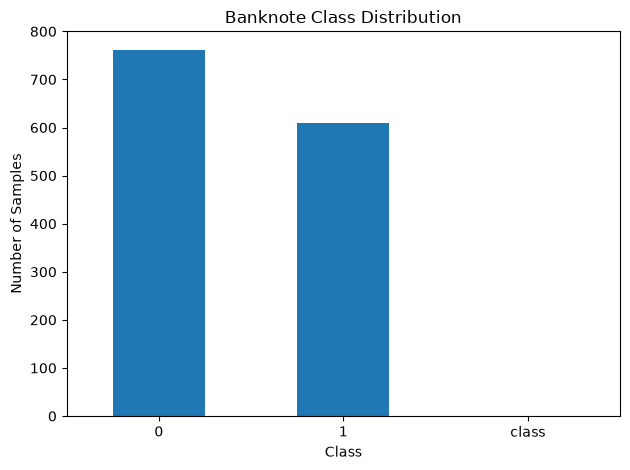

In [7]:
import matplotlib.pyplot as plt
class_counts.plot(kind="bar")

plt.title("Banknote Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
print(df["class"].value_counts(dropna=False))
print(df[df["class"] == "class"])

class
0        762
1        610
class      1
Name: count, dtype: int64
   variance  skewness  curtosis  entropy  class
0  variance  skewness  curtosis  entropy  class


In [10]:
import pandas as pd

columns = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

df = pd.read_csv(
    "BankNoteAuthentication.csv",
    header=None,
    names=columns
)

# Remove the accidental header row
df = df[df["class"] != "class"].copy()

# Convert all columns to numeric
df = df.astype(float)

# Reset the index
df.reset_index(drop=True, inplace=True)

print("Dataset shape:", df.shape)

print("\nClass distribution:")
print(df["class"].value_counts().sort_index())

Dataset shape: (1372, 5)

Class distribution:
class
0.0    762
1.0    610
Name: count, dtype: int64


In [11]:
print("Missing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
print(df.describe())

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Data types:
variance    float64
skewness    float64
curtosis    float64
entropy     float64
class       float64
dtype: object

Duplicate rows: 24

Statistical summary:
          variance     skewness     curtosis      entropy        class
count  1372.000000  1372.000000  1372.000000  1372.000000  1372.000000
mean      0.433735     1.922353     1.397627    -1.191657     0.444606
std       2.842763     5.869047     4.310030     2.101013     0.497103
min      -7.042100   -13.773100    -5.286100    -8.548200     0.000000
25%      -1.773000    -1.708200    -1.574975    -2.413450     0.000000
50%       0.496180     2.319650     0.616630    -0.586650     0.000000
75%       2.821475     6.814625     3.179250     0.394810     1.000000
max       6.824800    12.951600    17.927400     2.449500     1.000000


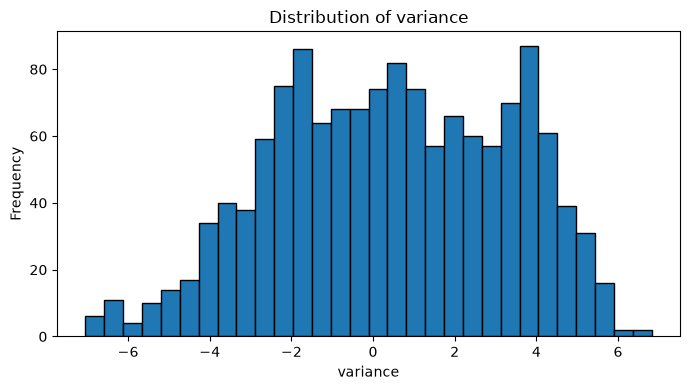

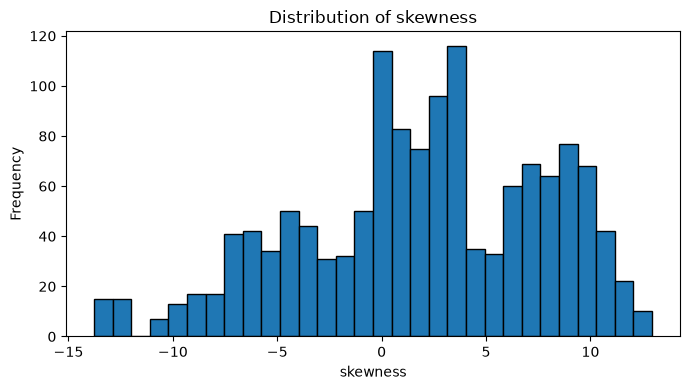

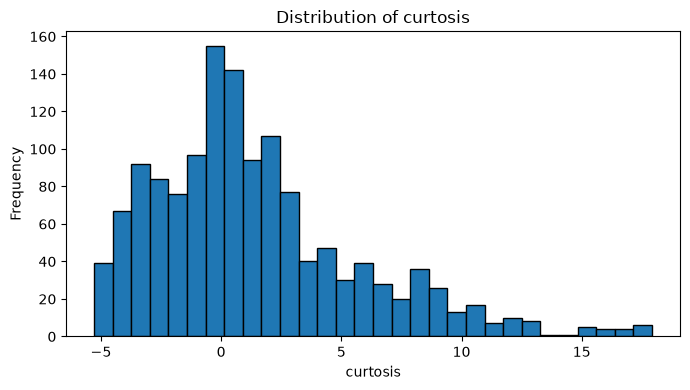

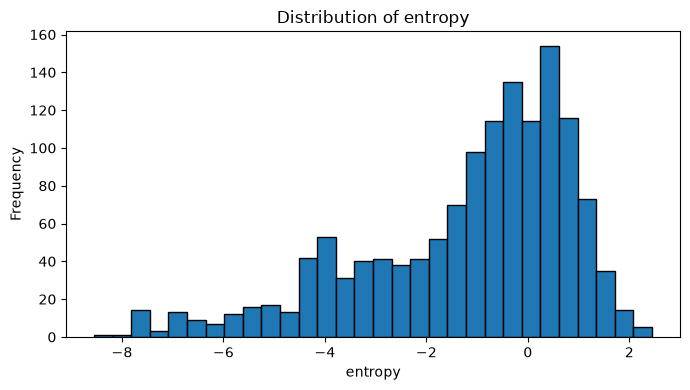

In [12]:
import matplotlib.pyplot as plt

features = ["variance", "skewness", "curtosis", "entropy"]

for feature in features:
    plt.figure(figsize=(7, 4))

    plt.hist(df[feature], bins=30, edgecolor="black")

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

In [13]:
features = ["variance", "skewness", "curtosis", "entropy"]

outlier_summary = []

for feature in features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": feature,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_summary)

print(outlier_df.round(3).to_string(index=False))

 Feature     Q1    Q3   IQR  Lower Bound  Upper Bound  Outlier Count
variance -1.773 2.821 4.594       -8.665        9.713              0
skewness -1.708 6.815 8.523      -14.492       19.599              0
curtosis -1.575 3.179 4.754       -8.706       10.311             59
 entropy -2.413 0.395 2.808       -6.626        4.607             33


In [14]:
features = ["variance", "skewness", "curtosis", "entropy"]

for feature in features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    mask = (
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    )

    print(f"\nFeature: {feature}")

    print(
        df.loc[mask]
        .groupby("class")
        .size()
        .rename("Outlier Count")
    )


Feature: variance
Series([], Name: Outlier Count, dtype: int64)

Feature: skewness
Series([], Name: Outlier Count, dtype: int64)

Feature: curtosis
class
1.0    59
Name: Outlier Count, dtype: int64

Feature: entropy
class
0.0    18
1.0    15
Name: Outlier Count, dtype: int64


          variance  skewness  curtosis  entropy
variance     1.000     0.264    -0.381    0.277
skewness     0.264     1.000    -0.787   -0.526
curtosis    -0.381    -0.787     1.000    0.319
entropy      0.277    -0.526     0.319    1.000


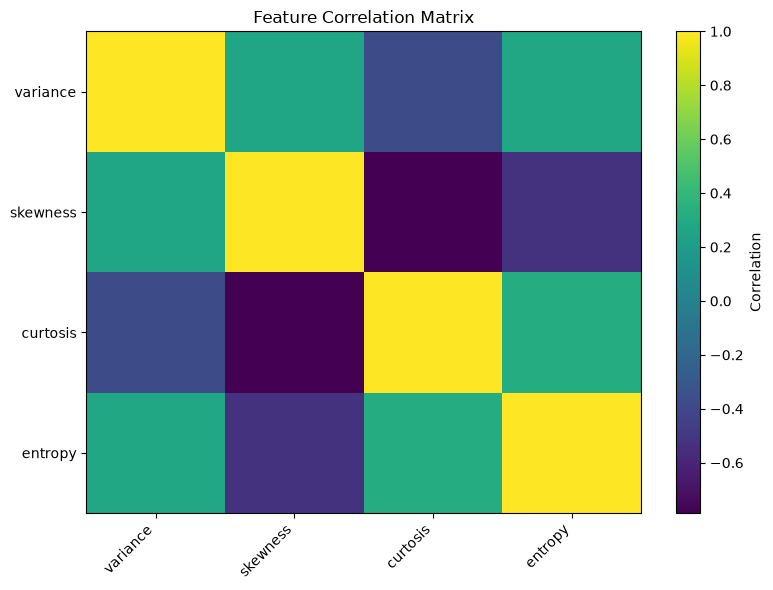

In [15]:
features = ["variance", "skewness", "curtosis", "entropy"]

correlation = df[features].corr()

print(correlation.round(3))

plt.figure(figsize=(8, 6))

plt.imshow(correlation, interpolation="nearest", aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(features)),
    features,
    rotation=45,
    ha="right"
)

plt.yticks(range(len(features)), features)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

Plot variance against skewness

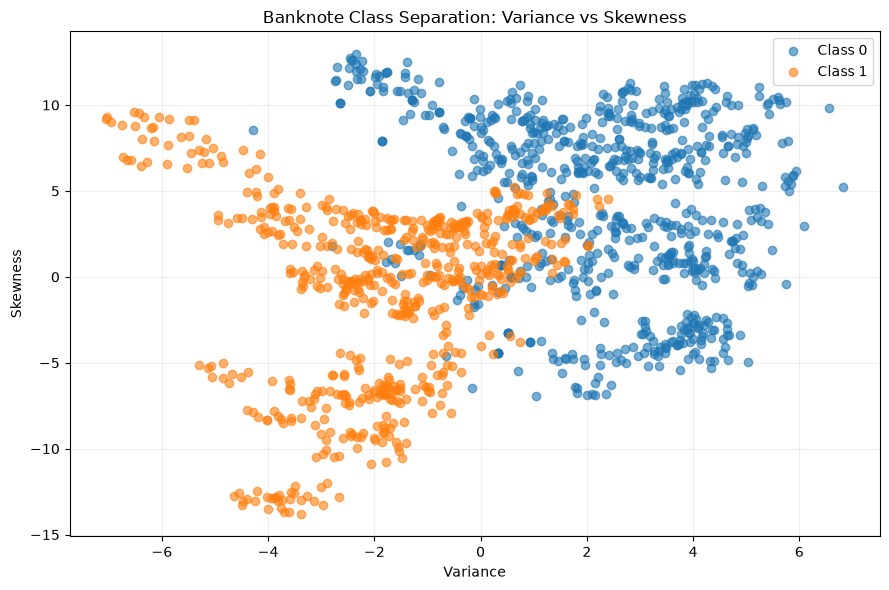

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for label in sorted(df["class"].unique()):
    subset = df[df["class"] == label]

    plt.scatter(
        subset["variance"],
        subset["skewness"],
        label=f"Class {int(label)}",
        alpha=0.6
    )

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Banknote Class Separation: Variance vs Skewness")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Implement stratified splitting

In [17]:
import random

# Separate features and target
feature_names = [
    "variance",
    "skewness",
    "curtosis",
    "entropy"
]

X = df[feature_names].values.tolist()
y = df["class"].tolist()

# Group sample indices by class
class_indices = {}

for i, label in enumerate(y):
    class_indices.setdefault(label, []).append(i)

# Reproducible split
random.seed(42)

train_indices = []
test_indices = []

for label, indices in class_indices.items():

    indices = indices.copy()
    random.shuffle(indices)

    split_index = int(len(indices) * 0.8)

    train_indices.extend(indices[:split_index])
    test_indices.extend(indices[split_index:])

# Shuffle indices within the final sets
random.shuffle(train_indices)
random.shuffle(test_indices)

# Create training and testing data
X_train = [X[i] for i in train_indices]
y_train = [y[i] for i in train_indices]

X_test = [X[i] for i in test_indices]
y_test = [y[i] for i in test_indices]

# Display results
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")

for label in sorted(set(y)):
    count = y_train.count(label)
    percentage = count / len(y_train) * 100
    print(f"Class {int(label)}: {count} ({percentage:.2f}%)")

print("\nTesting class distribution:")

for label in sorted(set(y)):
    count = y_test.count(label)
    percentage = count / len(y_test) * 100
    print(f"Class {int(label)}: {count} ({percentage:.2f}%)")

print("\nNumber of features:", len(X_train[0]))

Training samples: 1097
Testing samples: 275

Training class distribution:
Class 0: 609 (55.52%)
Class 1: 488 (44.48%)

Testing class distribution:
Class 0: 153 (55.64%)
Class 1: 122 (44.36%)

Number of features: 4


Implement Gini Impurity and Entropy from Scratch

In [18]:
def gini_impurity(y):
    """
    Calculate Gini impurity for a collection of class labels.
    """
    n = len(y)

    if n == 0:
        return 0.0

    counts = {}

    for label in y:
        counts[label] = counts.get(label, 0) + 1

    impurity = 1.0

    for count in counts.values():
        probability = count / n
        impurity -= probability ** 2

    return impurity

In [19]:
print("Mixed classes:", gini_impurity([0, 0, 0, 1, 1, 1]))
print("Pure class:", gini_impurity([0, 0, 0, 0]))
print("Empty node:", gini_impurity([]))

Mixed classes: 0.5
Pure class: 0.0
Empty node: 0.0


In [20]:
import math

def entropy(y):
    """
    Calculate entropy for a collection of class labels.
    """
    n = len(y)

    if n == 0:
        return 0.0

    counts = {}

    for label in y:
        counts[label] = counts.get(label, 0) + 1

    result = 0.0

    for count in counts.values():
        probability = count / n

        if probability > 0:
            result -= probability * math.log2(probability)

    return result

In [21]:
print("Mixed classes:", entropy([0, 0, 0, 1, 1, 1]))
print("Pure class:", entropy([0, 0, 0, 0]))
print("Empty node:", entropy([]))

Mixed classes: 1.0
Pure class: 0.0
Empty node: 0.0


Find the Best Feature and Threshold

Implement the weighted impurity calculation

In [22]:
def weighted_impurity(y_left, y_right, criterion="gini"):

    n_left = len(y_left)
    n_right = len(y_right)
    n_total = n_left + n_right

    if n_total == 0:
        return 0.0

    if criterion == "gini":
        impurity_func = gini_impurity
    elif criterion == "entropy":
        impurity_func = entropy
    else:
        raise ValueError("Criterion must be 'gini' or 'entropy'")

    left_impurity = impurity_func(y_left)
    right_impurity = impurity_func(y_right)

    weighted = (
        (n_left / n_total) * left_impurity
        + (n_right / n_total) * right_impurity
    )

    return weighted

Implement the best-split function

In [23]:
def find_best_split(X, y, criterion="gini", min_samples_leaf=1):

    n_samples = len(X)

    if n_samples < 2 * min_samples_leaf:
        return None

    n_features = len(X[0])

    if criterion == "gini":
        impurity_func = gini_impurity
    elif criterion == "entropy":
        impurity_func = entropy
    else:
        raise ValueError("Criterion must be 'gini' or 'entropy'")

    parent_impurity = impurity_func(y)

    best_gain = 0.0
    best_split = None

    for feature_index in range(n_features):

        values = sorted(set(
            row[feature_index] for row in X
        ))

        if len(values) < 2:
            continue

        thresholds = [
            (values[i] + values[i + 1]) / 2
            for i in range(len(values) - 1)
        ]

        for threshold in thresholds:

            left_indices = []
            right_indices = []

            for i, row in enumerate(X):

                if row[feature_index] <= threshold:
                    left_indices.append(i)
                else:
                    right_indices.append(i)

            if (
                len(left_indices) < min_samples_leaf
                or len(right_indices) < min_samples_leaf
            ):
                continue

            y_left = [y[i] for i in left_indices]
            y_right = [y[i] for i in right_indices]

            split_impurity = weighted_impurity(
                y_left,
                y_right,
                criterion
            )

            gain = parent_impurity - split_impurity

            if gain > best_gain:

                best_gain = gain

                best_split = {
                    "feature_index": feature_index,
                    "threshold": threshold,
                    "gain": gain,
                    "left_indices": left_indices,
                    "right_indices": right_indices
                }

    return best_split

Test the function on your training data

In [24]:
best_split = find_best_split(
    X_train,
    y_train,
    criterion="gini"
)

if best_split is not None:

    feature_names = [
        "variance",
        "skewness",
        "curtosis",
        "entropy"
    ]

    feature_name = feature_names[
        best_split["feature_index"]
    ]

    print("Best feature:", feature_name)
    print("Best threshold:", best_split["threshold"])
    print("Information gain:", best_split["gain"])

else:
    print("No valid split found.")

Best feature: variance
Best threshold: 0.320165
Information gain: 0.24316072454312637


In [25]:
best_split_entropy = find_best_split(
    X_train,
    y_train,
    criterion="entropy"
)

if best_split_entropy is not None:

    print("Best feature index:",
          best_split_entropy["feature_index"])

    print("Best threshold:",
          best_split_entropy["threshold"])

    print("Information gain:",
          best_split_entropy["gain"])

Best feature index: 0
Best threshold: 0.7602949999999999
Information gain: 0.3966675523826436


#### Build the Decision Tree Recursively

In [26]:
class DecisionTreeScratch:

    def __init__(
        self,
        criterion="gini",
        max_depth=5,
        min_samples_split=2,
        min_samples_leaf=1
    ):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.tree = None

    def _majority_class(self, y):
        counts = {}

        for label in y:
            counts[label] = counts.get(label, 0) + 1

        return max(counts, key=counts.get)

    def _build_tree(self, X, y, depth):

        # Create a leaf prediction
        majority = self._majority_class(y)

        # Stop 1: Pure node
        if len(set(y)) == 1:
            return {
                "type": "leaf",
                "prediction": y[0]
            }

        # Stop 2: Maximum depth reached
        if depth >= self.max_depth:
            return {
                "type": "leaf",
                "prediction": majority
            }

        # Stop 3: Too few samples to split
        if len(y) < self.min_samples_split:
            return {
                "type": "leaf",
                "prediction": majority
            }

        # Stop 4: No useful split available
        split = find_best_split(
            X,
            y,
            criterion=self.criterion,
            min_samples_leaf=self.min_samples_leaf
        )

        if split is None:
            return {
                "type": "leaf",
                "prediction": majority
            }

        # Partition the observations
        left_indices = split["left_indices"]
        right_indices = split["right_indices"]

        X_left = [X[i] for i in left_indices]
        y_left = [y[i] for i in left_indices]

        X_right = [X[i] for i in right_indices]
        y_right = [y[i] for i in right_indices]

        # Recursively build both children
        return {
            "type": "node",
            "feature_index": split["feature_index"],
            "threshold": split["threshold"],
            "gain": split["gain"],
            "samples": len(y),
            "prediction": majority,
            "left": self._build_tree(
                X_left, y_left, depth + 1
            ),
            "right": self._build_tree(
                X_right, y_right, depth + 1
            )
        }

    def fit(self, X, y):

        if not X or not y:
            raise ValueError("Training data cannot be empty.")

        if len(X) != len(y):
            raise ValueError(
                "X and y must have the same number of samples."
            )

        if self.criterion not in ("gini", "entropy"):
            raise ValueError(
                "Criterion must be 'gini' or 'entropy'."
            )

        if self.max_depth < 0:
            raise ValueError("max_depth cannot be negative.")

        if self.min_samples_split < 2:
            raise ValueError("min_samples_split must be at least 2.")

        if self.min_samples_leaf < 1:
            raise ValueError("min_samples_leaf must be at least 1.")

        self.tree = self._build_tree(X, y, depth=0)

        return self

    def _predict_one(self, row, node):

        if node["type"] == "leaf":
            return node["prediction"]

        feature_index = node["feature_index"]
        threshold = node["threshold"]

        if row[feature_index] <= threshold:
            return self._predict_one(row, node["left"])

        return self._predict_one(row, node["right"])

    def predict(self, X):

        if self.tree is None:
            raise ValueError("Train the tree using fit() first.")

        return [
            self._predict_one(row, self.tree)
            for row in X
        ]

In [27]:
manual_tree = DecisionTreeScratch(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1
)

manual_tree.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


Display the learned tree structure

In [28]:
feature_names = [
    "variance",
    "skewness",
    "curtosis",
    "entropy"
]


def print_tree(node, feature_names, depth=0):

    indent = "  " * depth

    if node["type"] == "leaf":
        print(
            indent +
            f"Predict Class {node['prediction']}"
        )
        return

    feature = feature_names[node["feature_index"]]
    threshold = node["threshold"]

    print(
        indent +
        f"If {feature} <= {threshold:.4f}:"
    )

    print_tree(
        node["left"],
        feature_names,
        depth + 1
    )

    print(
        indent +
        f"Else ({feature} > {threshold:.4f}):"
    )

    print_tree(
        node["right"],
        feature_names,
        depth + 1
    )


print_tree(manual_tree.tree, feature_names)

If variance <= 0.3202:
  If skewness <= 7.5653:
    If variance <= -0.4586:
      If curtosis <= 6.7456:
        Predict Class 1.0
      Else (curtosis > 6.7456):
        If skewness <= -2.4614:
          Predict Class 1.0
        Else (skewness > -2.4614):
          Predict Class 0.0
    Else (variance > -0.4586):
      If curtosis <= 5.9303:
        If skewness <= 5.4535:
          Predict Class 1.0
        Else (skewness > 5.4535):
          Predict Class 0.0
      Else (curtosis > 5.9303):
        Predict Class 0.0
  Else (skewness > 7.5653):
    If variance <= -4.8358:
      Predict Class 1.0
    Else (variance > -4.8358):
      Predict Class 0.0
Else (variance > 0.3202):
  If curtosis <= -4.3856:
    If variance <= 3.2222:
      Predict Class 1.0
    Else (variance > 3.2222):
      Predict Class 0.0
  Else (curtosis > -4.3856):
    If variance <= 1.5922:
      If curtosis <= -2.2722:
        If skewness <= 5.6574:
          Predict Class 1.0
        Else (skewness > 5.6574):
    

In [29]:
y_pred = manual_tree.predict(X_test)

print("First 20 actual labels:")
print(y_test[:20])

print("\nFirst 20 predictions:")
print(y_pred[:20])

First 20 actual labels:
[0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0]

First 20 predictions:
[0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0]


Evaluate Your Manual Decision Tree

In [30]:
def confusion_matrix_binary(y_true, y_pred):
    tn = fp = fn = tp = 0

    for actual, predicted in zip(y_true, y_pred):
        if actual == 0 and predicted == 0:
            tn += 1
        elif actual == 0 and predicted == 1:
            fp += 1
        elif actual == 1 and predicted == 0:
            fn += 1
        elif actual == 1 and predicted == 1:
            tp += 1

    return tn, fp, fn, tp


def evaluate_classifier(y_true, y_pred):
    if len(y_true) != len(y_pred):
        raise ValueError("Actual and predicted lengths must match.")

    if len(y_true) == 0:
        raise ValueError("Evaluation data cannot be empty.")

    tn, fp, fn, tp = confusion_matrix_binary(y_true, y_pred)

    accuracy = (tp + tn) / len(y_true)

    precision = tp / (tp + fp) if tp + fp else 0.0

    recall = tp / (tp + fn) if tp + fn else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall
        else 0.0
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

In [31]:
# Predict the test-set labels
y_pred = manual_tree.predict(X_test)

# Calculate evaluation metrics
results = evaluate_classifier(y_test, y_pred)

print("Manual Decision Tree Evaluation")
print("-" * 35)

for metric, value in results.items():
    if metric in ["TN", "FP", "FN", "TP"]:
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.4f}")

Manual Decision Tree Evaluation
-----------------------------------
Accuracy: 0.9673
Precision: 0.9520
Recall: 0.9754
F1-score: 0.9636
TN: 147
FP: 6
FN: 3
TP: 119


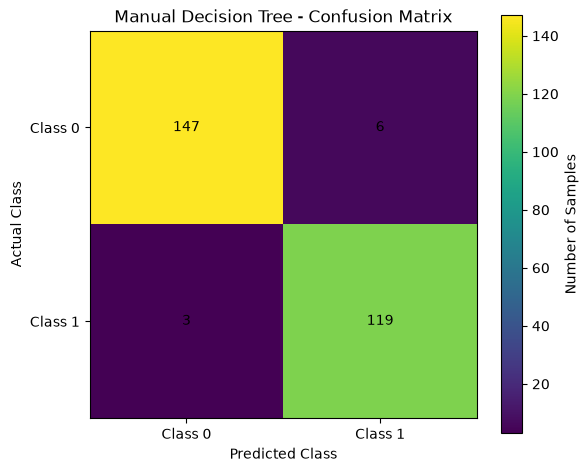

In [32]:
import matplotlib.pyplot as plt

tn, fp, fn, tp = confusion_matrix_binary(y_test, y_pred)

cm = [
    [tn, fp],
    [fn, tp]
]

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")

plt.title("Manual Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks([0, 1], ["Class 0", "Class 1"])
plt.yticks([0, 1], ["Class 0", "Class 1"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i][j], ha="center", va="center")

plt.colorbar(label="Number of Samples")
plt.tight_layout()
plt.show()

#### Compare Your Manual Decision Tree with Scikit-learn

Train Scikit-learn's Decision Tree

In [33]:
from sklearn.tree import DecisionTreeClassifier

# Train the Scikit-learn model
sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

sklearn_tree.fit(X_train, y_train)

# Predict the test set
sklearn_predictions = sklearn_tree.predict(X_test).tolist()

print("Scikit-learn Decision Tree trained successfully!")

Scikit-learn Decision Tree trained successfully!


Evaluate the Scikit-learn model

In [34]:
sklearn_results = evaluate_classifier(
    y_test,
    sklearn_predictions
)

print("Scikit-learn Decision Tree Evaluation")
print("-" * 40)

for metric, value in sklearn_results.items():
    if metric in ["TN", "FP", "FN", "TP"]:
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.4f}")

Scikit-learn Decision Tree Evaluation
----------------------------------------
Accuracy: 0.9673
Precision: 0.9520
Recall: 0.9754
F1-score: 0.9636
TN: 147
FP: 6
FN: 3
TP: 119


#### Compare both models

In [35]:
import pandas as pd

manual_results = evaluate_classifier(
    y_test,
    manual_tree.predict(X_test)
)

sklearn_results = evaluate_classifier(
    y_test,
    sklearn_predictions
)

comparison = pd.DataFrame({
    "Manual Decision Tree": {
        key: value
        for key, value in manual_results.items()
        if key in ["Accuracy", "Precision", "Recall", "F1-score"]
    },
    "Scikit-learn Decision Tree": {
        key: value
        for key, value in sklearn_results.items()
        if key in ["Accuracy", "Precision", "Recall", "F1-score"]
    }
})

print(comparison.round(4))

           Manual Decision Tree  Scikit-learn Decision Tree
Accuracy                 0.9673                      0.9673
Precision                0.9520                      0.9520
Recall                   0.9754                      0.9754
F1-score                 0.9636                      0.9636


In [38]:
import matplotlib
matplotlib.use("TkAgg")

import matplotlib.pyplot as plt

In [42]:
%matplotlib inline

import matplotlib.pyplot as plt

print("Matplotlib backend:", plt.get_backend())
print("Matplotlib is interactive:", plt.isinteractive())

Matplotlib backend: inline
Matplotlib is interactive: True


Tree saved as manual_decision_tree.png


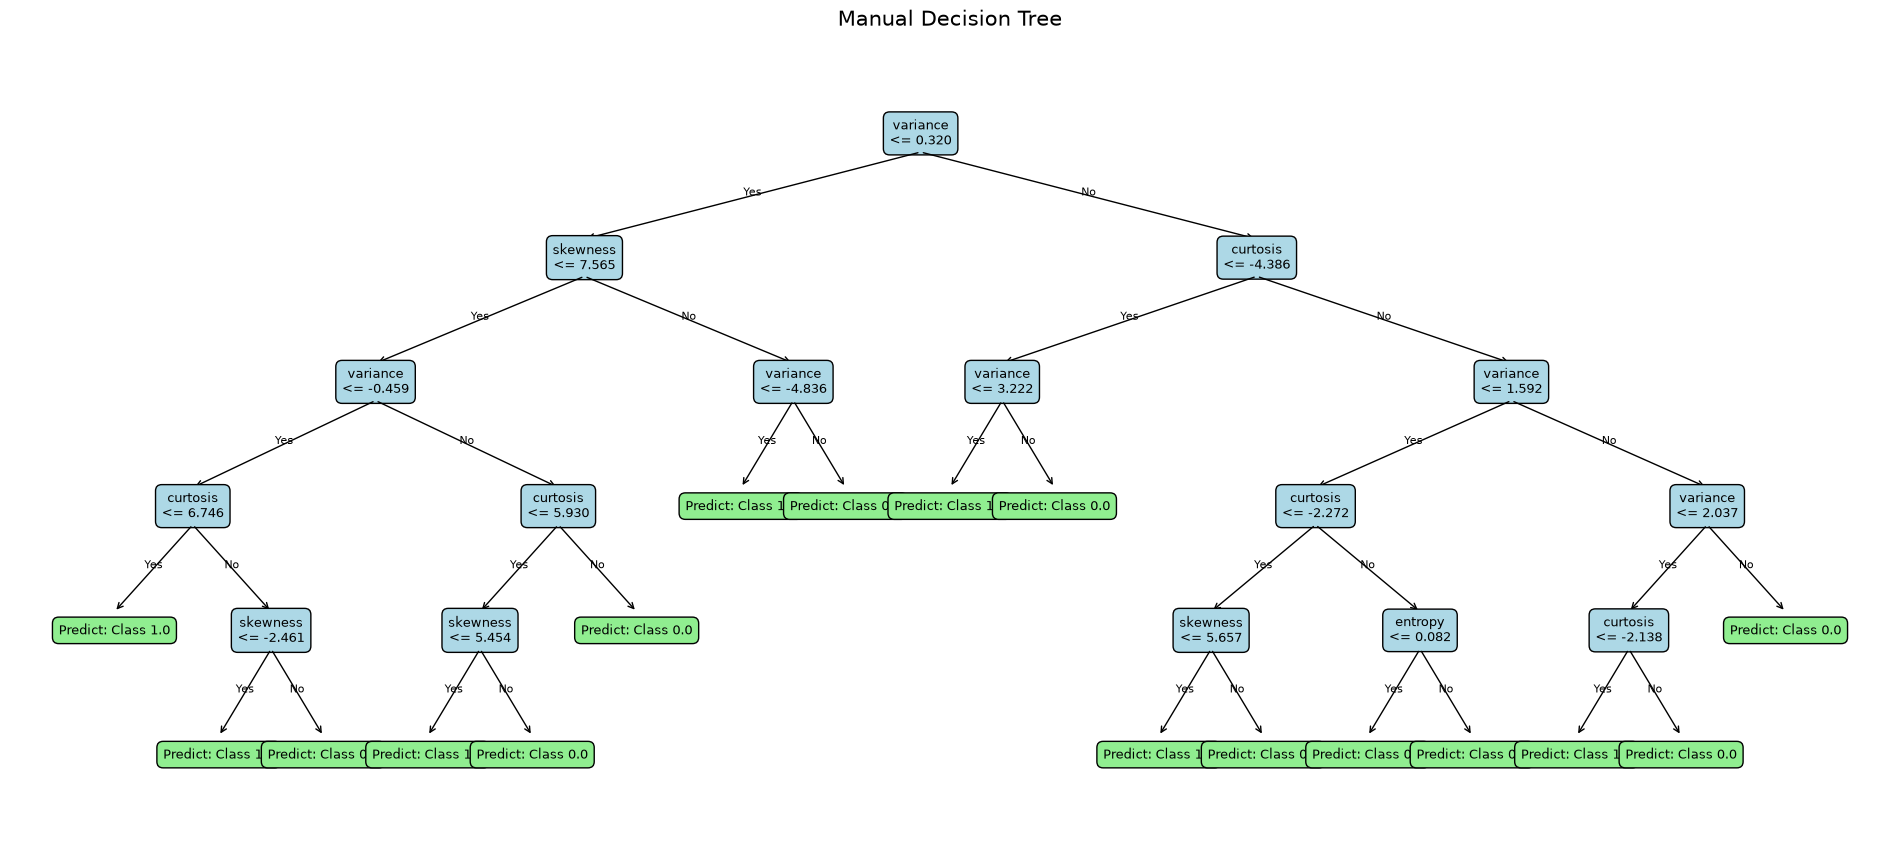

In [45]:

import matplotlib.pyplot as plt


def plot_manual_tree(root, feature_names):

    if root is None:
        print("Error: Tree is empty. Train the model first.")
        return

    fig, ax = plt.subplots(figsize=(20, 10))
    ax.axis("off")

    positions = {}
    leaf_counter = [0]

    # Calculate node positions
    def layout(node, depth=0):

        if node["type"] == "leaf":
            x = leaf_counter[0]
            leaf_counter[0] += 1

        else:
            left_x = layout(node["left"], depth + 1)
            right_x = layout(node["right"], depth + 1)
            x = (left_x + right_x) / 2

        positions[id(node)] = (x, -depth)
        return x

    layout(root)

    # Draw nodes and branches
    def draw(node):

        x, y = positions[id(node)]

        if node["type"] == "leaf":
            label = f"Predict: Class {node['prediction']}"
            color = "lightgreen"

        else:
            feature = feature_names[node["feature_index"]]
            threshold = node["threshold"]

            label = f"{feature}\n<= {threshold:.3f}"
            color = "lightblue"

        ax.text(
            x, y, label,
            ha="center",
            va="center",
            fontsize=9,
            bbox=dict(
                boxstyle="round,pad=0.5",
                facecolor=color,
                edgecolor="black"
            )
        )

        if node["type"] == "node":

            for key, branch in [
                ("left", "Yes"),
                ("right", "No")
            ]:

                child = node[key]
                cx, cy = positions[id(child)]

                ax.annotate(
                    "",
                    xy=(cx, cy + 0.15),
                    xytext=(x, y - 0.15),
                    arrowprops=dict(arrowstyle="->")
                )

                ax.text(
                    (x + cx) / 2,
                    (y + cy) / 2,
                    branch,
                    ha="center",
                    fontsize=8
                )

                draw(child)

    draw(root)

    # Set limits to include all nodes
    max_depth = max(
        -y for x, y in positions.values()
    )

    ax.set_xlim(-1, max(1, leaf_counter[0]))
    ax.set_ylim(-max_depth - 0.8, 0.8)

    ax.set_title("Manual Decision Tree", fontsize=15)

    fig.subplots_adjust(
        left=0.03,
        right=0.97,
        top=0.90,
        bottom=0.08
    )

    # Save the figure
    fig.savefig(
        "manual_decision_tree.png",
        dpi=200,
        bbox_inches="tight"
    )

    print("Tree saved as manual_decision_tree.png")

    # Display the figure
    plt.show()
    plt.close(fig)


feature_names = [
    "variance",
    "skewness",
    "curtosis",
    "entropy"
]

plot_manual_tree(
    manual_tree.tree,
    feature_names
)



### Experiment with Gini, Entropy, and Maximum Depth

In [46]:
import pandas as pd

depths = [1, 2, 5, 10]
criteria = ["gini", "entropy"]

manual_experiment_results = []

for criterion in criteria:

    for depth in depths:

        model = DecisionTreeScratch(
            criterion=criterion,
            max_depth=depth,
            min_samples_split=2,
            min_samples_leaf=1
        )

        # Train the model
        model.fit(X_train, y_train)

        # Training predictions
        train_predictions = model.predict(X_train)

        # Testing predictions
        test_predictions = model.predict(X_test)

        # Calculate metrics
        train_metrics = evaluate_classifier(
            y_train,
            train_predictions
        )

        test_metrics = evaluate_classifier(
            y_test,
            test_predictions
        )

        manual_experiment_results.append({
            "Criterion": criterion,
            "Max Depth": depth,
            "Train Accuracy": train_metrics["Accuracy"],
            "Test Accuracy": test_metrics["Accuracy"],
            "Test Precision": test_metrics["Precision"],
            "Test Recall": test_metrics["Recall"],
            "Test F1": test_metrics["F1-score"]
        })

manual_results_df = pd.DataFrame(
    manual_experiment_results
)

print(manual_results_df.round(4).to_string(index=False))

Criterion  Max Depth  Train Accuracy  Test Accuracy  Test Precision  Test Recall  Test F1
     gini          1          0.8505         0.8655          0.8295       0.8770   0.8526
     gini          2          0.9180         0.9127          0.9016       0.9016   0.9016
     gini          5          0.9854         0.9673          0.9520       0.9754   0.9636
     gini         10          1.0000         0.9818          0.9606       1.0000   0.9799
  entropy          1          0.8377         0.8509          0.7872       0.9098   0.8441
  entropy          2          0.8970         0.8909          0.9107       0.8361   0.8718
  entropy          5          0.9991         0.9818          0.9680       0.9918   0.9798
  entropy         10          1.0000         0.9818          0.9680       0.9918   0.9798


Repeat the experiment with Scikit-learn

In [47]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

sklearn_experiment_results = []

for criterion in criteria:

    for depth in depths:

        model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            min_samples_split=2,
            min_samples_leaf=1,
            random_state=42
        )

        model.fit(X_train, y_train)

        train_predictions = model.predict(X_train)
        test_predictions = model.predict(X_test)

        sklearn_experiment_results.append({
            "Criterion": criterion,
            "Max Depth": depth,
            "Train Accuracy": accuracy_score(
                y_train, train_predictions
            ),
            "Test Accuracy": accuracy_score(
                y_test, test_predictions
            ),
            "Test Precision": precision_score(
                y_test, test_predictions,
                zero_division=0
            ),
            "Test Recall": recall_score(
                y_test, test_predictions,
                zero_division=0
            ),
            "Test F1": f1_score(
                y_test, test_predictions,
                zero_division=0
            )
        })

sklearn_results_df = pd.DataFrame(
    sklearn_experiment_results
)

print(sklearn_results_df.round(4).to_string(index=False))

Criterion  Max Depth  Train Accuracy  Test Accuracy  Test Precision  Test Recall  Test F1
     gini          1          0.8505         0.8655          0.8295       0.8770   0.8526
     gini          2          0.9180         0.9127          0.9016       0.9016   0.9016
     gini          5          0.9854         0.9673          0.9520       0.9754   0.9636
     gini         10          1.0000         0.9818          0.9606       1.0000   0.9799
  entropy          1          0.8377         0.8509          0.7872       0.9098   0.8441
  entropy          2          0.8970         0.8909          0.9107       0.8361   0.8718
  entropy          5          0.9991         0.9818          0.9680       0.9918   0.9798
  entropy         10          1.0000         0.9818          0.9680       0.9918   0.9798


#### Plot the effect of maximum depth

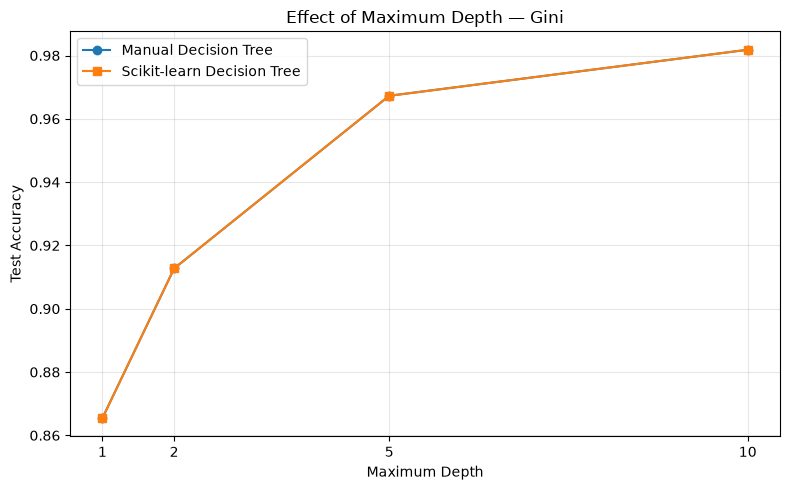

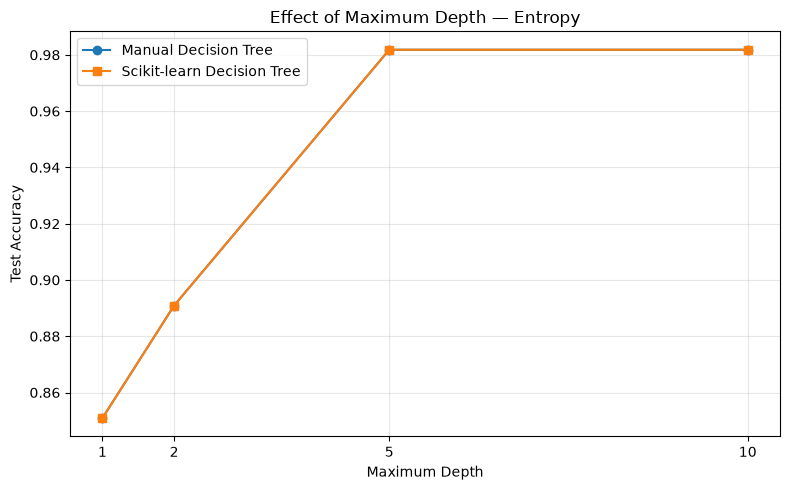

In [48]:
import matplotlib.pyplot as plt

for criterion in criteria:

    manual_subset = manual_results_df[
        manual_results_df["Criterion"] == criterion
    ]

    sklearn_subset = sklearn_results_df[
        sklearn_results_df["Criterion"] == criterion
    ]

    plt.figure(figsize=(8, 5))

    plt.plot(
        manual_subset["Max Depth"],
        manual_subset["Test Accuracy"],
        marker="o",
        label="Manual Decision Tree"
    )

    plt.plot(
        sklearn_subset["Max Depth"],
        sklearn_subset["Test Accuracy"],
        marker="s",
        label="Scikit-learn Decision Tree"
    )

    plt.xlabel("Maximum Depth")
    plt.ylabel("Test Accuracy")
    plt.title(f"Effect of Maximum Depth — {criterion.title()}")
    plt.xticks(depths)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Gini Impurity Results
Increasing the maximum depth improves test accuracy across the depths you tested. However, this does not establish that depth 10 is the best possible setting. We would need to investigate additional depths and evaluate generalization before making that decision.

Entropy Results
A depth-5 tree may be preferable to a depth-10 tree when both achieve comparable performance, because the shallower tree is generally easier to interpret.

Neither criterion consistently outperforms the other at every depth.

Gini performs better at depths 1 and 2 in your experiment.
Entropy performs better at depth 5.
Their results are nearly identical at depth 10.

The preferred criterion depends on the evaluation results and the intended use of the model.

the blue and orange lines overlap almost completely.

This means the two implementations achieved almost the same test accuracy at the displayed depths.

That is a positive result, but remember that matching accuracy does not guarantee identical predictions or identical tree structures.

Different trees can achieve the same accuracy while making different errors.

#### Plot Decision Boundaries

In [49]:
# Select variance and skewness
feature_indices = [0, 1]

X_train_2d = [
    [row[0], row[1]]
    for row in X_train
]

X_test_2d = [
    [row[0], row[1]]
    for row in X_test
]

feature_names_2d = [
    "variance",
    "skewness"
]

print("Training samples:", len(X_train_2d))
print("Testing samples:", len(X_test_2d))
print("Features:", feature_names_2d)

Training samples: 1097
Testing samples: 275
Features: ['variance', 'skewness']


In [50]:
from sklearn.tree import DecisionTreeClassifier

# Manual Decision Tree
manual_tree_2d = DecisionTreeScratch(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1
)

manual_tree_2d.fit(
    X_train_2d,
    y_train
)

# Scikit-learn Decision Tree
sklearn_tree_2d = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

sklearn_tree_2d.fit(
    X_train_2d,
    y_train
)

print("Both two-feature visualization models are trained.")

Both two-feature visualization models are trained.


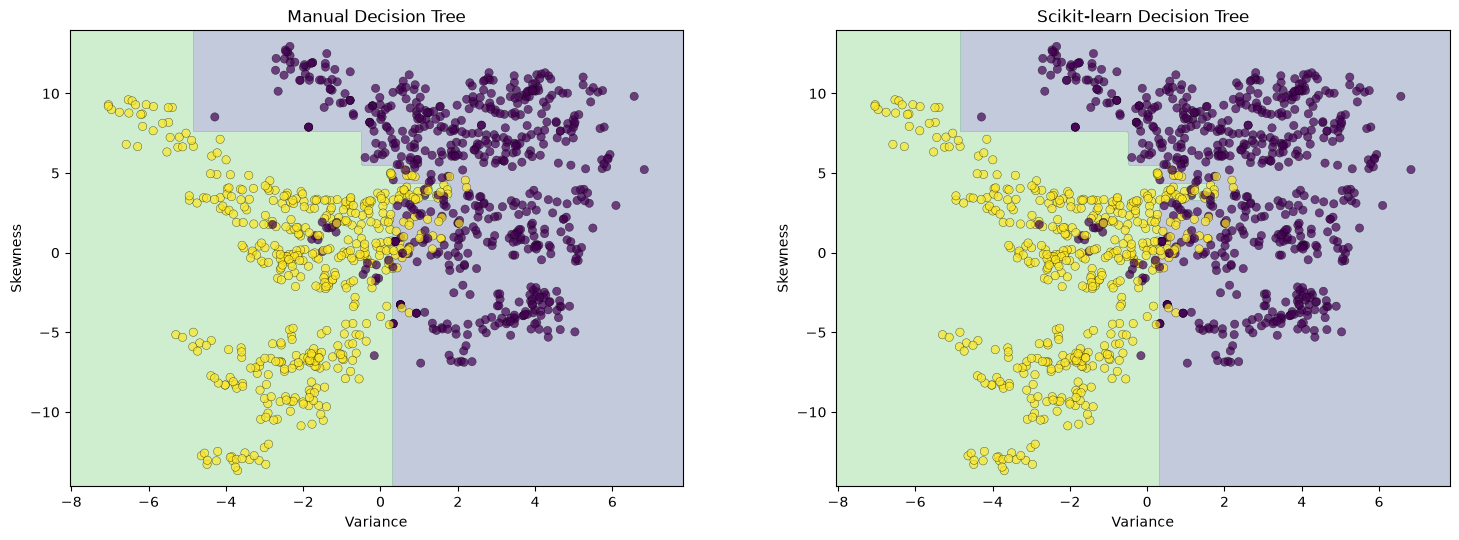

In [51]:

import numpy as np
import matplotlib.pyplot as plt

# Convert training data to NumPy arrays
X_train_2d_np = np.array(X_train_2d)
y_train_np = np.array(y_train)

# Define plotting limits
x_min = X_train_2d_np[:, 0].min() - 1
x_max = X_train_2d_np[:, 0].max() + 1

y_min = X_train_2d_np[:, 1].min() - 1
y_max = X_train_2d_np[:, 1].max() + 1

# Create a grid of variance and skewness values
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.column_stack([
    xx.ravel(),
    yy.ravel()
])

# Predict each grid point
manual_grid_predictions = np.array(
    manual_tree_2d.predict(grid.tolist())
).reshape(xx.shape)

sklearn_grid_predictions = sklearn_tree_2d.predict(
    grid
).reshape(xx.shape)

# Create two side-by-side plots
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6)
)

models = [
    (
        axes[0],
        manual_grid_predictions,
        "Manual Decision Tree"
    ),
    (
        axes[1],
        sklearn_grid_predictions,
        "Scikit-learn Decision Tree"
    )
]

for ax, predictions, title in models:

    ax.contourf(
        xx,
        yy,
        predictions,
        alpha=0.3,
        levels=[-0.5, 0.5, 1.5]
    )

    ax.scatter(
        X_train_2d_np[:, 0],
        X_train_2d_np[:, 1],
        c=y_train_np,
        edgecolors="black",
        linewidths=0.3,
        alpha=0.7
    )

    ax.set_title(title)
    ax.set_xlabel("Variance")
    ax.set_ylabel("Skewness")

fig.subplots_adjust(
    left=0.06,
    right=0.98,
    bottom=0.12,
    top=0.88,
    wspace=0.25
)

plt.show()



### Part B - Linear SVM from Scratch

StandardScaler from scratch

In [52]:
import numpy as np


class StandardScalerScratch:

    def __init__(self):
        self.mean_ = None
        self.scale_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=float)

        if X.ndim != 2 or X.shape[0] == 0:
            raise ValueError("X must be a non-empty 2D array.")

        if not np.isfinite(X).all():
            raise ValueError("X contains missing or infinite values.")

        self.mean_ = np.mean(X, axis=0)
        std = np.std(X, axis=0)

        # Avoid division by zero for constant features
        self.scale_ = np.where(std == 0, 1.0, std)

        return self

    def transform(self, X):
        if self.mean_ is None or self.scale_ is None:
            raise ValueError("Call fit() before transform().")

        X = np.asarray(X, dtype=float)

        if X.ndim != 2 or X.shape[1] != len(self.mean_):
            raise ValueError("X has an incorrect shape.")

        if not np.isfinite(X).all():
            raise ValueError("X contains missing or infinite values.")

        return (X - self.mean_) / self.scale_

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)


# Fit using training data only
scaler = StandardScalerScratch()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nTraining feature means:")
print(np.round(X_train_scaled.mean(axis=0), 4))

print("\nTraining feature standard deviations:")
print(np.round(X_train_scaled.std(axis=0), 4))

Training shape: (1097, 4)
Testing shape: (275, 4)

Training feature means:
[ 0. -0. -0.  0.]

Training feature standard deviations:
[1. 1. 1. 1.]


Convert Labels to −1 and +1

In [53]:
# Convert labels to NumPy arrays
y_train_array = np.asarray(y_train)
y_test_array = np.asarray(y_test)

# Validate binary labels
if not np.isin(y_train_array, [0, 1]).all():
    raise ValueError("Training labels must contain only 0 and 1.")

if not np.isin(y_test_array, [0, 1]).all():
    raise ValueError("Testing labels must contain only 0 and 1.")

# Map 0 -> -1 and 1 -> +1
y_train_svm = np.where(y_train_array == 0, -1, 1)
y_test_svm = np.where(y_test_array == 0, -1, 1)

print("Original training labels:", np.unique(y_train_array))
print("SVM training labels:", np.unique(y_train_svm))

print("\nTraining class counts:")
print("-1:", np.sum(y_train_svm == -1))
print("+1:", np.sum(y_train_svm == 1))

Original training labels: [0. 1.]
SVM training labels: [-1  1]

Training class counts:
-1: 609
+1: 488


Implement Hinge Loss

In [54]:
def hinge_loss(y_true, scores):
    y_true = np.asarray(y_true, dtype=float)
    scores = np.asarray(scores, dtype=float)

    if y_true.shape != scores.shape:
        raise ValueError("Labels and scores must have matching shapes.")

    margins = y_true * scores

    return np.maximum(0.0, 1.0 - margins)


def svm_objective(X, y, w, b, C=1.0):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    w = np.asarray(w, dtype=float)

    scores = X @ w + b
    losses = hinge_loss(y, scores)

    regularization = 0.5 * np.dot(w, w)
    data_loss = C * np.mean(losses)

    return regularization + data_loss

Implement the Linear Soft-Margin SVM

In [55]:
class LinearSVMScratch:

    def __init__(
        self,
        C=1.0,
        learning_rate=0.01,
        epochs=2000
    ):
        if C <= 0:
            raise ValueError("C must be positive.")

        if learning_rate <= 0:
            raise ValueError("Learning rate must be positive.")

        if epochs < 1:
            raise ValueError("Epochs must be at least 1.")

        self.C = C
        self.learning_rate = learning_rate
        self.epochs = epochs

        self.w = None
        self.b = 0.0
        self.loss_history = []

    def fit(self, X, y):

        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        if X.ndim != 2 or X.shape[0] == 0:
            raise ValueError("X must be a non-empty 2D array.")

        if y.ndim != 1 or len(y) != len(X):
            raise ValueError("y must match the number of rows in X.")

        if not np.isfinite(X).all():
            raise ValueError("X contains missing or infinite values.")

        if not np.isin(y, [-1, 1]).all():
            raise ValueError("SVM labels must be -1 and +1.")

        n_samples, n_features = X.shape

        # Initialize parameters
        self.w = np.zeros(n_features, dtype=float)
        self.b = 0.0

        self.loss_history = []

        # Batch subgradient descent
        for epoch in range(self.epochs):

            scores = X @ self.w + self.b
            margins = y * scores

            # Observations with positive hinge loss
            active = margins < 1.0

            # Subgradients of the regularized objective
            grad_w = self.w - self.C * (
                X[active].T @ y[active]
            ) / n_samples

            grad_b = -self.C * np.sum(
                y[active]
            ) / n_samples

            # Update parameters
            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b

            # Record objective after the update
            objective = svm_objective(
                X, y, self.w, self.b, self.C
            )

            self.loss_history.append(objective)

        return self

    def decision_function(self, X):

        if self.w is None:
            raise ValueError("Train the model before prediction.")

        X = np.asarray(X, dtype=float)

        if X.ndim != 2 or X.shape[1] != len(self.w):
            raise ValueError("X has an incorrect shape.")

        if not np.isfinite(X).all():
            raise ValueError("X contains missing or infinite values.")

        return X @ self.w + self.b

    def predict(self, X):

        scores = self.decision_function(X)

        # Return SVM labels: -1 and +1
        return np.where(scores >= 0, 1, -1)

Train the SVM

In [56]:
svm_model = LinearSVMScratch(
    C=1.0,
    learning_rate=0.01,
    epochs=2000
)

svm_model.fit(
    X_train_scaled,
    y_train_svm
)

print("Linear SVM trained successfully!")

print("\nLearned weights:")
print(svm_model.w)

print("\nLearned bias:")
print(svm_model.b)

print("\nInitial objective:", svm_model.loss_history[0])
print("Final objective:", svm_model.loss_history[-1])

Linear SVM trained successfully!

Learned weights:
[-0.50404492 -0.28105535 -0.02699658 -0.03064743]

Learned bias:
-0.25088422971740854

Initial objective: 0.9925708460257361
Final objective: 0.6847581139997532


Plot the Training Objective

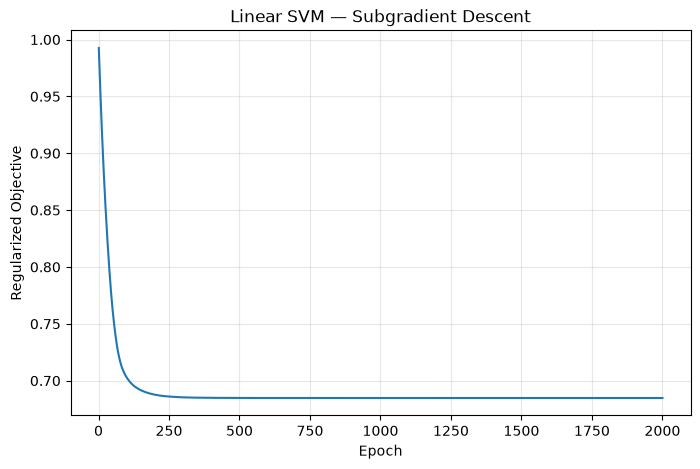

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(svm_model.loss_history) + 1),
    svm_model.loss_history
)

plt.xlabel("Epoch")
plt.ylabel("Regularized Objective")
plt.title("Linear SVM — Subgradient Descent")
plt.grid(alpha=0.3)

plt.show()

Evaluate the SVM

In [58]:
# Predict SVM labels
y_pred_svm = svm_model.predict(X_test_scaled)

# Convert predictions: -1 -> 0 and +1 -> 1
y_pred_original = np.where(y_pred_svm == -1, 0, 1)

# Evaluate with your existing function
svm_results = evaluate_classifier(
    y_test_array.tolist(),
    y_pred_original.tolist()
)

print("Linear SVM Evaluation")
print("-" * 30)

for metric, value in svm_results.items():
    if metric in ["TN", "FP", "FN", "TP"]:
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.4f}")

Linear SVM Evaluation
------------------------------
Accuracy: 0.8473
Precision: 0.9348
Recall: 0.7049
F1-score: 0.8037
TN: 147
FP: 6
FN: 36
TP: 86


Train both SVMs on the same two features

In [59]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Convert the two features to arrays
X_train_2d = np.asarray(X_train_2d, dtype=float)
X_test_2d = np.asarray(X_test_2d, dtype=float)

y_train_array = np.asarray(y_train)
y_test_array = np.asarray(y_test)

# Scale using training data only
svm_scaler_2d = StandardScaler()

X_train_2d_scaled = svm_scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = svm_scaler_2d.transform(X_test_2d)

# Convert labels: 0 -> -1, 1 -> +1
y_train_svm_2d = np.where(y_train_array == 0, -1, 1)
y_test_svm_2d = np.where(y_test_array == 0, -1, 1)

print("Training shape:", X_train_2d_scaled.shape)
print("Testing shape:", X_test_2d_scaled.shape)
print("SVM classes:", np.unique(y_train_svm_2d))

Training shape: (1097, 2)
Testing shape: (275, 2)
SVM classes: [-1  1]


Train the manual and Scikit-learn SVMs

In [60]:
# Manual SVM
manual_svm_2d = LinearSVMScratch(
    C=1.0,
    learning_rate=0.01,
    epochs=2000
)

manual_svm_2d.fit(
    X_train_2d_scaled,
    y_train_svm_2d
)

# Scikit-learn linear SVM
sklearn_svm_2d = SVC(
    kernel="linear",
    C=1.0
)

sklearn_svm_2d.fit(
    X_train_2d_scaled,
    y_train_svm_2d
)

print("Both SVM models trained successfully.")

Both SVM models trained successfully.


Complete visualization code

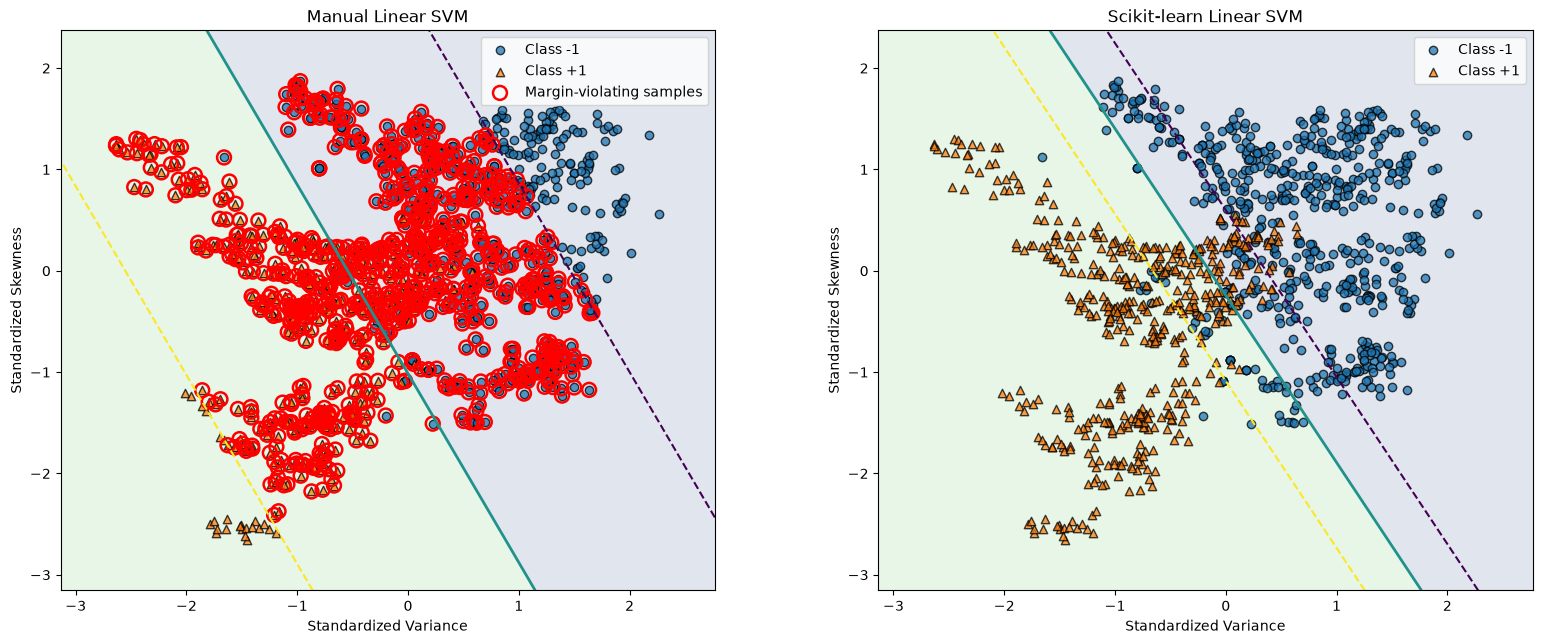

Saved: svm_decision_boundaries.png
Manual SVM margin violations: 928
Total training samples: 1097


In [61]:
def plot_svm_comparison(
    X,
    y,
    manual_model,
    sklearn_model,
    margin_model_scaler
):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)

    # The models operate in scaled feature space
    x_min = X[:, 0].min() - 0.5
    x_max = X[:, 0].max() + 0.5
    y_min = X[:, 1].min() - 0.5
    y_max = X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400)
    )

    grid = np.column_stack([
        xx.ravel(),
        yy.ravel()
    ])

    # Decision scores for both models
    manual_scores = manual_model.decision_function(grid)
    sklearn_scores = sklearn_model.decision_function(grid)

    manual_scores = manual_scores.reshape(xx.shape)
    sklearn_scores = sklearn_scores.reshape(xx.shape)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # ----------------------------------
    # Plot 1: Manual SVM
    # ----------------------------------
    ax = axes[0]

    ax.contourf(
        xx,
        yy,
        manual_scores,
        levels=[-100, 0, 100],
        alpha=0.15
    )

    # Separating line and margins
    ax.contour(
        xx,
        yy,
        manual_scores,
        levels=[-1, 0, 1],
        linestyles=["--", "-", "--"],
        linewidths=[1.5, 2.0, 1.5]
    )

    # Calculate training margins
    train_scores = manual_model.decision_function(X)
    margins = y * train_scores

    # Margin-violating samples: y * f(x) < 1
    violating = margins < 1.0

    # Plot each class separately
    for label, marker, name in [
        (-1, "o", "Class -1"),
        (1, "^", "Class +1")
    ]:
        class_mask = y == label

        ax.scatter(
            X[class_mask, 0],
            X[class_mask, 1],
            marker=marker,
            label=name,
            edgecolors="black",
            alpha=0.75
        )

    # Highlight margin-violating samples
    ax.scatter(
        X[violating, 0],
        X[violating, 1],
        s=100,
        facecolors="none",
        edgecolors="red",
        linewidths=1.8,
        label="Margin-violating samples"
    )

    ax.set_title("Manual Linear SVM")
    ax.set_xlabel("Standardized Variance")
    ax.set_ylabel("Standardized Skewness")
    ax.legend()

    # ----------------------------------
    # Plot 2: Scikit-learn SVM
    # ----------------------------------
    ax = axes[1]

    ax.contourf(
        xx,
        yy,
        sklearn_scores,
        levels=[-100, 0, 100],
        alpha=0.15
    )

    ax.contour(
        xx,
        yy,
        sklearn_scores,
        levels=[-1, 0, 1],
        linestyles=["--", "-", "--"],
        linewidths=[1.5, 2.0, 1.5]
    )

    for label, marker, name in [
        (-1, "o", "Class -1"),
        (1, "^", "Class +1")
    ]:
        class_mask = y == label

        ax.scatter(
            X[class_mask, 0],
            X[class_mask, 1],
            marker=marker,
            label=name,
            edgecolors="black",
            alpha=0.75
        )

    ax.set_title("Scikit-learn Linear SVM")
    ax.set_xlabel("Standardized Variance")
    ax.set_ylabel("Standardized Skewness")
    ax.legend()

    fig.subplots_adjust(
        left=0.06,
        right=0.98,
        bottom=0.10,
        top=0.90,
        wspace=0.25
    )

    fig.savefig(
        "svm_decision_boundaries.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved: svm_decision_boundaries.png")
    print(
        "Manual SVM margin violations:",
        int(np.sum(violating))
    )
    print(
        "Total training samples:",
        len(y)
    )


plot_svm_comparison(
    X_train_2d_scaled,
    y_train_svm_2d,
    manual_svm_2d,
    sklearn_svm_2d,
    svm_scaler_2d
)

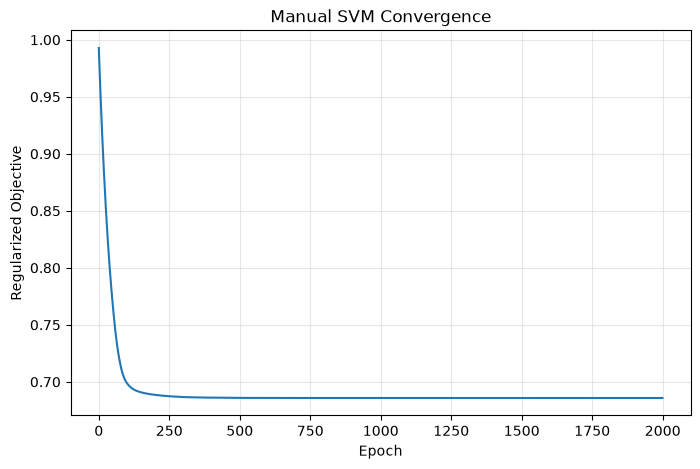

Initial objective: 0.992810397192405
Final objective: 0.6858429250132844
Manual weights: [-0.49798568 -0.26716262]
Manual bias: -0.2710391978122095


In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(manual_svm_2d.loss_history)

plt.xlabel("Epoch")
plt.ylabel("Regularized Objective")
plt.title("Manual SVM Convergence")
plt.grid(alpha=0.3)

plt.show()

print("Initial objective:", manual_svm_2d.loss_history[0])
print("Final objective:", manual_svm_2d.loss_history[-1])

print("Manual weights:", manual_svm_2d.w)
print("Manual bias:", manual_svm_2d.b)

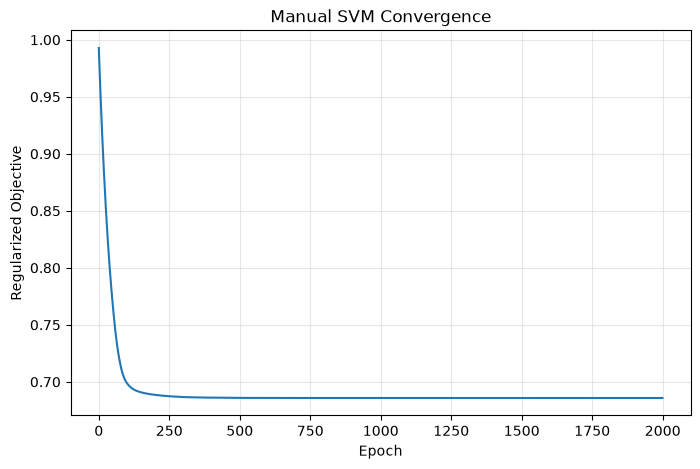

Initial objective: 0.992810397192405
Final objective: 0.6858429250132844
Manual weights: [-0.49798568 -0.26716262]
Manual bias: -0.2710391978122095


In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(manual_svm_2d.loss_history)

plt.xlabel("Epoch")
plt.ylabel("Regularized Objective")
plt.title("Manual SVM Convergence")
plt.grid(alpha=0.3)

plt.show()

print("Initial objective:", manual_svm_2d.loss_history[0])
print("Final objective:", manual_svm_2d.loss_history[-1])

print("Manual weights:", manual_svm_2d.w)
print("Manual bias:", manual_svm_2d.b)

In [63]:
import numpy as np

manual_scores = manual_svm_2d.decision_function(
    X_train_2d_scaled
)

manual_margins = y_train_svm_2d * manual_scores

misclassified = manual_margins <= 0
inside_margin = (manual_margins > 0) & (manual_margins < 1)
on_margin = np.isclose(manual_margins, 1.0)
outside_margin = manual_margins > 1

print("Total training samples:", len(y_train_svm_2d))
print("Margin violations:", np.sum(manual_margins < 1))
print("Misclassified samples:", np.sum(misclassified))
print("Correct but inside margin:", np.sum(inside_margin))
print("Approximately on margin:", np.sum(on_margin))
print("Correct and outside margin:", np.sum(outside_margin))

Total training samples: 1097
Margin violations: 928
Misclassified samples: 162
Correct but inside margin: 766
Approximately on margin: 0
Correct and outside margin: 169


Prepare the experiment

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [66]:
def evaluate_svm(model, X_train, y_train, X_test, y_test):

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    return {
        "Train Accuracy": accuracy_score(
            y_train, train_pred
        ),
        "Test Accuracy": accuracy_score(
            y_test, test_pred
        ),
        "Test Precision": precision_score(
            y_test, test_pred, pos_label=1,
            zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, test_pred, pos_label=1,
            zero_division=0
        ),
        "Test F1": f1_score(
            y_test, test_pred, pos_label=1,
            zero_division=0
        )
    }

the effect of regularization C

In [67]:
C_values = [0.01, 0.1, 1, 10, 100]

manual_C_results = []
sklearn_C_results = []

for C in C_values:

    # Manual SVM
    manual_model = LinearSVMScratch(
        C=C,
        learning_rate=0.01,
        epochs=2000
    )

    manual_model.fit(
        X_train_2d_scaled,
        y_train_svm_2d
    )

    manual_metrics = evaluate_svm(
        manual_model,
        X_train_2d_scaled,
        y_train_svm_2d,
        X_test_2d_scaled,
        y_test_svm_2d
    )

    manual_C_results.append({
        "C": C,
        **manual_metrics,
        "Final Objective": manual_model.loss_history[-1]
    })

    # Scikit-learn SVM
    sklearn_model = SVC(
        kernel="linear",
        C=C
    )

    sklearn_model.fit(
        X_train_2d_scaled,
        y_train_svm_2d
    )

    sklearn_metrics = evaluate_svm(
        sklearn_model,
        X_train_2d_scaled,
        y_train_svm_2d,
        X_test_2d_scaled,
        y_test_svm_2d
    )

    sklearn_C_results.append({
        "C": C,
        **sklearn_metrics
    })

manual_C_df = pd.DataFrame(manual_C_results)
sklearn_C_df = pd.DataFrame(sklearn_C_results)

print("MANUAL SVM — EFFECT OF C")
print(manual_C_df.round(4).to_string(index=False))

print("\nSCIKIT-LEARN SVM — EFFECT OF C")
print(sklearn_C_df.round(4).to_string(index=False))

MANUAL SVM — EFFECT OF C
     C  Train Accuracy  Test Accuracy  Test Precision  Test Recall  Test F1  Final Objective
  0.01          0.5643         0.5709          1.0000       0.0328   0.0635           0.0099
  0.10          0.5643         0.5709          1.0000       0.0328   0.0635           0.0940
  1.00          0.8523         0.8400          0.9333       0.6885   0.7925           0.6858
 10.00          0.8778         0.8764          0.8929       0.8197   0.8547           4.0113
100.00          0.8751         0.8945          0.8908       0.8689   0.8797          30.4906

SCIKIT-LEARN SVM — EFFECT OF C
     C  Train Accuracy  Test Accuracy  Test Precision  Test Recall  Test F1
  0.01          0.8769         0.8764          0.8929       0.8197   0.8547
  0.10          0.8760         0.8982          0.8917       0.8770   0.8843
  1.00          0.8778         0.9018          0.8926       0.8852   0.8889
 10.00          0.8742         0.8982          0.8852       0.8852   0.8852
100.0

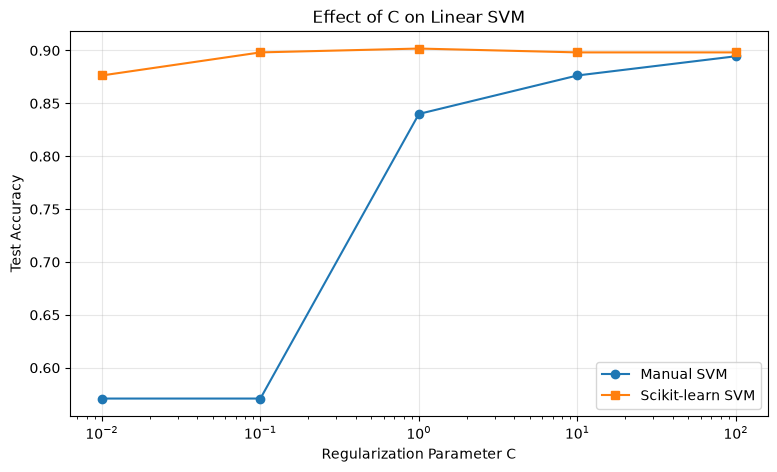

In [68]:
plt.figure(figsize=(9, 5))

plt.plot(
    manual_C_df["C"],
    manual_C_df["Test Accuracy"],
    marker="o",
    label="Manual SVM"
)

plt.plot(
    sklearn_C_df["C"],
    sklearn_C_df["Test Accuracy"],
    marker="s",
    label="Scikit-learn SVM"
)

plt.xscale("log")
plt.xlabel("Regularization Parameter C")
plt.ylabel("Test Accuracy")
plt.title("Effect of C on Linear SVM")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

the effect of learning rate

In [69]:
learning_rates = [0.001, 0.005, 0.01, 0.05, 0.1]

learning_rate_results = []
learning_rate_models = {}

for lr in learning_rates:

    model = LinearSVMScratch(
        C=1.0,
        learning_rate=lr,
        epochs=2000
    )

    model.fit(
        X_train_2d_scaled,
        y_train_svm_2d
    )

    metrics = evaluate_svm(
        model,
        X_train_2d_scaled,
        y_train_svm_2d,
        X_test_2d_scaled,
        y_test_svm_2d
    )

    learning_rate_results.append({
        "Learning Rate": lr,
        **metrics,
        "Final Objective": model.loss_history[-1]
    })

    learning_rate_models[lr] = model

learning_rate_df = pd.DataFrame(learning_rate_results)

print(learning_rate_df.round(4).to_string(index=False))

 Learning Rate  Train Accuracy  Test Accuracy  Test Precision  Test Recall  Test F1  Final Objective
         0.001          0.8696         0.8727          0.9223       0.7787   0.8444           0.6886
         0.005          0.8532         0.8400          0.9333       0.6885   0.7925           0.6858
         0.010          0.8523         0.8400          0.9333       0.6885   0.7925           0.6858
         0.050          0.8523         0.8400          0.9333       0.6885   0.7925           0.6858
         0.100          0.8523         0.8400          0.9333       0.6885   0.7925           0.6858


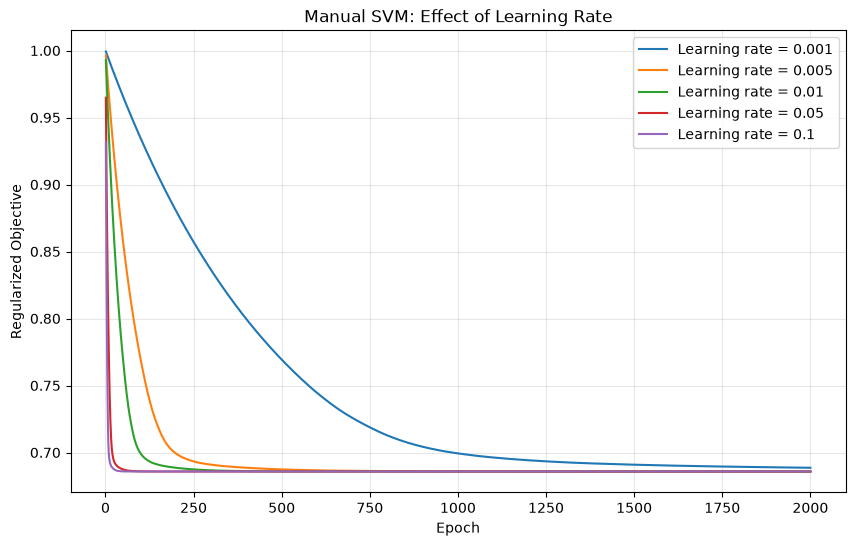

In [70]:
plt.figure(figsize=(10, 6))

for lr, model in learning_rate_models.items():

    plt.plot(
        range(1, len(model.loss_history) + 1),
        model.loss_history,
        label=f"Learning rate = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Regularized Objective")
plt.title("Manual SVM: Effect of Learning Rate")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

the effect of iterations

In [71]:
epoch_values = [100, 500, 1000, 2000, 5000]

epoch_results = []
epoch_models = {}

for epochs in epoch_values:

    model = LinearSVMScratch(
        C=1.0,
        learning_rate=0.01,
        epochs=epochs
    )

    model.fit(
        X_train_2d_scaled,
        y_train_svm_2d
    )

    metrics = evaluate_svm(
        model,
        X_train_2d_scaled,
        y_train_svm_2d,
        X_test_2d_scaled,
        y_test_svm_2d
    )

    epoch_results.append({
        "Epochs": epochs,
        **metrics,
        "Final Objective": model.loss_history[-1]
    })

    epoch_models[epochs] = model

epoch_df = pd.DataFrame(epoch_results)

print(epoch_df.round(4).to_string(index=False))

 Epochs  Train Accuracy  Test Accuracy  Test Precision  Test Recall  Test F1  Final Objective
    100          0.8751         0.8873          0.9099       0.8279   0.8670           0.6991
    500          0.8578         0.8436          0.9341       0.6967   0.7981           0.6859
   1000          0.8532         0.8400          0.9333       0.6885   0.7925           0.6858
   2000          0.8523         0.8400          0.9333       0.6885   0.7925           0.6858
   5000          0.8523         0.8400          0.9333       0.6885   0.7925           0.6858


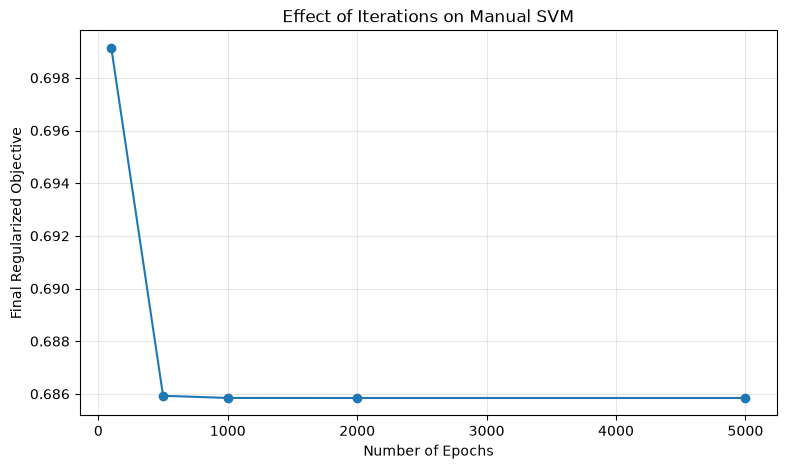

In [72]:
plt.figure(figsize=(9, 5))

plt.plot(
    epoch_df["Epochs"],
    epoch_df["Final Objective"],
    marker="o"
)

plt.xlabel("Number of Epochs")
plt.ylabel("Final Regularized Objective")
plt.title("Effect of Iterations on Manual SVM")
plt.grid(alpha=0.3)

plt.show()

In [73]:
manual_final = LinearSVMScratch(
    C=1.0,
    learning_rate=0.01,
    epochs=2000
)

manual_final.fit(
    X_train_2d_scaled,
    y_train_svm_2d
)

sklearn_final = SVC(
    kernel="linear",
    C=1.0
)

sklearn_final.fit(
    X_train_2d_scaled,
    y_train_svm_2d
)

manual_final_metrics = evaluate_svm(
    manual_final,
    X_train_2d_scaled,
    y_train_svm_2d,
    X_test_2d_scaled,
    y_test_svm_2d
)

sklearn_final_metrics = evaluate_svm(
    sklearn_final,
    X_train_2d_scaled,
    y_train_svm_2d,
    X_test_2d_scaled,
    y_test_svm_2d
)

comparison_df = pd.DataFrame({
    "Manual SVM": manual_final_metrics,
    "Scikit-learn SVM": sklearn_final_metrics
})

print(comparison_df.round(4))

                Manual SVM  Scikit-learn SVM
Train Accuracy      0.8523            0.8778
Test Accuracy       0.8400            0.9018
Test Precision      0.9333            0.8926
Test Recall         0.6885            0.8852
Test F1             0.7925            0.8889


The manual optimizer may not have converged sufficiently.
The two models may have different optimization behavior.

### Part C - Kernel SVM and Nonlinear Boundaries

In [74]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Generate the nonlinear dataset
X, y = make_moons(
    n_samples=500,
    noise=0.20,
    random_state=42
)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Scale features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Dataset shape:", X.shape)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Classes:", np.unique(y))



Dataset shape: (500, 2)
Training samples: 375
Testing samples: 125
Classes: [0 1]


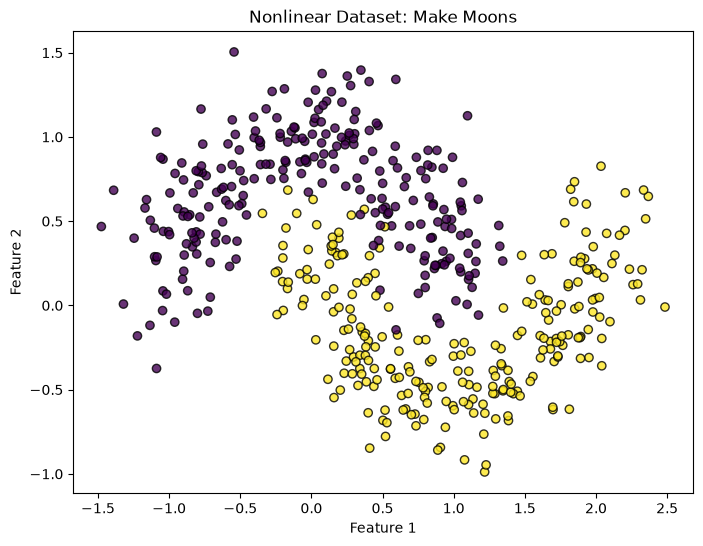

In [75]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    edgecolors="black",
    alpha=0.8
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Nonlinear Dataset: Make Moons")

plt.show()

Expected observation: The two classes form interleaving crescents. A single straight line will generally struggle to separate them.

Train three SVM models

In [76]:
from sklearn.svm import SVC

# 1. Linear kernel
linear_svm = SVC(
    kernel="linear",
    C=1.0
)

# 2. Polynomial kernel
poly_svm = SVC(
    kernel="poly",
    degree=3,
    C=1.0,
    gamma="scale",
    coef0=1.0
)

# 3. RBF kernel
rbf_svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

# Train all models
linear_svm.fit(X_train_scaled, y_train)
poly_svm.fit(X_train_scaled, y_train)
rbf_svm.fit(X_train_scaled, y_train)

print("All three SVM models trained successfully.")

All three SVM models trained successfully.


C=1.0

Controls the penalty for margin violations. We keep it the same across the models for this initial comparison.

degree=3

Sets the polynomial kernel's degree to three.

gamma="scale"

Allows Scikit-learn to determine a suitable gamma value based on the training data.

coef0=1.0

Controls the independent term in the polynomial kernel.

For the polynomial kernel, the decision function depends on:

$$ K(x,z)=(\gamma x^Tz+\text{coef0})^d $$

For the RBF kernel:

$$ K(x,z)=\exp(-\gamma\|x-z\|^2) $$

The RBF kernel measures similarity based on the distance between observations.

Plot the three decision boundaries

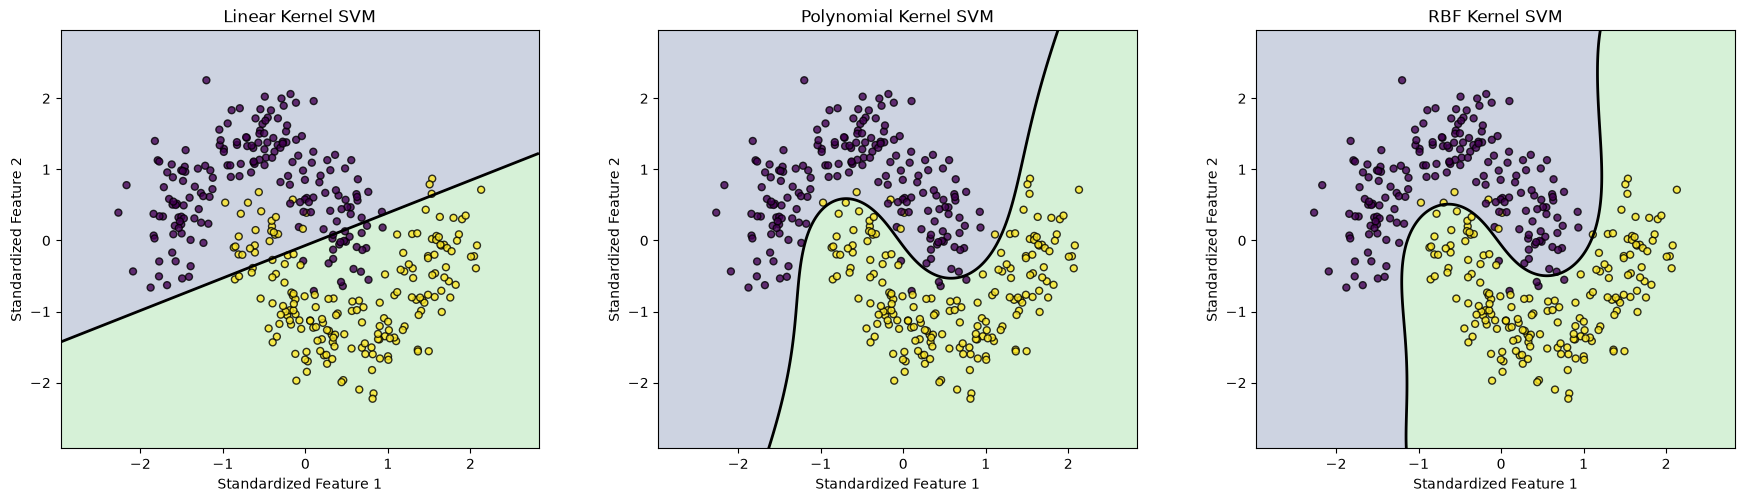

In [77]:

import matplotlib.pyplot as plt
import numpy as np

# Create a grid covering the scaled feature space
x_min = X_train_scaled[:, 0].min() - 0.7
x_max = X_train_scaled[:, 0].max() + 0.7

y_min = X_train_scaled[:, 1].min() - 0.7
y_max = X_train_scaled[:, 1].max() + 0.7

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)

grid = np.column_stack([
    xx.ravel(),
    yy.ravel()
])

models = [
    ("Linear Kernel SVM", linear_svm),
    ("Polynomial Kernel SVM", poly_svm),
    ("RBF Kernel SVM", rbf_svm)
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5.5)
)

for ax, (title, model) in zip(axes, models):

    # Predict the class for each grid point
    predictions = model.predict(grid).reshape(xx.shape)

    # Draw decision regions
    ax.contourf(
        xx,
        yy,
        predictions,
        alpha=0.25,
        levels=[-0.5, 0.5, 1.5]
    )

    # Draw the decision boundary
    scores = model.decision_function(grid).reshape(xx.shape)

    ax.contour(
        xx,
        yy,
        scores,
        levels=[0],
        colors="black",
        linewidths=2
    )

    # Draw training observations
    ax.scatter(
        X_train_scaled[:, 0],
        X_train_scaled[:, 1],
        c=y_train,
        edgecolors="black",
        alpha=0.8,
        s=25
    )

    ax.set_title(title)
    ax.set_xlabel("Standardized Feature 1")
    ax.set_ylabel("Standardized Feature 2")

fig.subplots_adjust(
    left=0.05,
    right=0.98,
    bottom=0.12,
    top=0.88,
    wspace=0.25
)

plt.show()



Linear kernel

The decision boundary is a straight line. It may misclassify observations because the classes have a nonlinear arrangement.

Polynomial kernel

The boundary can curve to represent more complex relationships. Its shape depends on the polynomial degree and other parameters.

RBF kernel

The boundary can adapt to more flexible nonlinear patterns. It often performs well on the make_moons dataset, although performance depends on the noise and hyperparameters.

The RBF kernel is not automatically the best choice for every nonlinear dataset.

Compare the models quantitatively

In [78]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, model in models:

    predictions = model.predict(X_test_scaled)

    results.append({
        "Model": name,
        "Training Accuracy": accuracy_score(
            y_train,
            model.predict(X_train_scaled)
        ),
        "Test Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_test,
            predictions,
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

                Model  Training Accuracy  Test Accuracy  Precision  Recall  F1-score
    Linear Kernel SVM             0.8613          0.856     0.8667  0.8387    0.8525
Polynomial Kernel SVM             0.9707          0.984     1.0000  0.9677    0.9836
       RBF Kernel SVM             0.9680          0.984     1.0000  0.9677    0.9836


#### the Effect of Polynomial Degree, C, and Gamma

Polynomial Degree

The polynomial kernel is:

K(x,z)=(γx
T
z+r)
d

In [79]:
import pandas as pd

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

degrees = [2, 3, 4, 5]

degree_results = []
degree_models = {}

for degree in degrees:

    model = SVC(
        kernel="poly",
        degree=degree,
        C=1.0,
        gamma="scale",
        coef0=1.0
    )

    model.fit(X_train_scaled, y_train)

    train_predictions = model.predict(X_train_scaled)
    test_predictions = model.predict(X_test_scaled)

    degree_results.append({
        "Degree": degree,
        "Train Accuracy": accuracy_score(
            y_train, train_predictions
        ),
        "Test Accuracy": accuracy_score(
            y_test, test_predictions
        ),
        "Test F1": f1_score(
            y_test, test_predictions
        )
    })

    degree_models[degree] = model

degree_df = pd.DataFrame(degree_results)

print(degree_df.round(4).to_string(index=False))

 Degree  Train Accuracy  Test Accuracy  Test F1
      2          0.8560          0.848   0.8376
      3          0.9707          0.984   0.9836
      4          0.9760          0.984   0.9836
      5          0.9867          0.992   0.9919


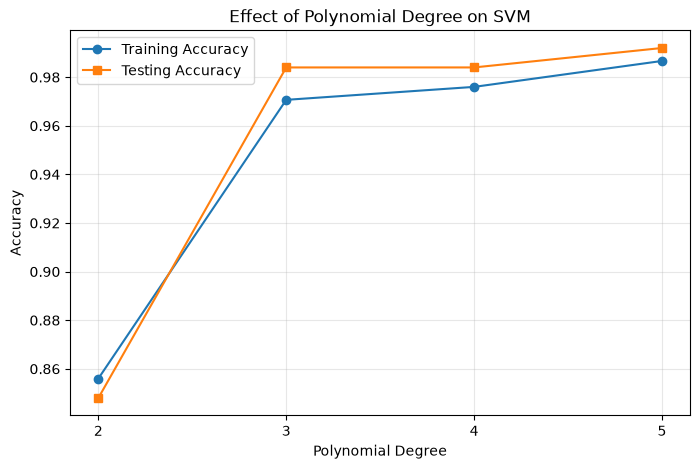

In [80]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    degree_df["Degree"],
    degree_df["Train Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    degree_df["Degree"],
    degree_df["Test Accuracy"],
    marker="s",
    label="Testing Accuracy"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("Accuracy")
plt.title("Effect of Polynomial Degree on SVM")
plt.xticks(degrees)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

the Effect of Regularization C

In [81]:
C_values = [0.01, 0.1, 1, 10, 100]

C_results = []
C_models = {}

for C in C_values:

    model = SVC(
        kernel="rbf",
        C=C,
        gamma="scale"
    )

    model.fit(X_train_scaled, y_train)

    train_predictions = model.predict(X_train_scaled)
    test_predictions = model.predict(X_test_scaled)

    C_results.append({
        "C": C,
        "Train Accuracy": accuracy_score(
            y_train, train_predictions
        ),
        "Test Accuracy": accuracy_score(
            y_test, test_predictions
        ),
        "Test F1": f1_score(
            y_test, test_predictions
        )
    })

    C_models[C] = model

C_df = pd.DataFrame(C_results)

print(C_df.round(4).to_string(index=False))

     C  Train Accuracy  Test Accuracy  Test F1
  0.01          0.8613          0.872   0.8750
  0.10          0.9173          0.920   0.9167
  1.00          0.9680          0.984   0.9836
 10.00          0.9813          0.992   0.9919
100.00          0.9813          0.992   0.9920


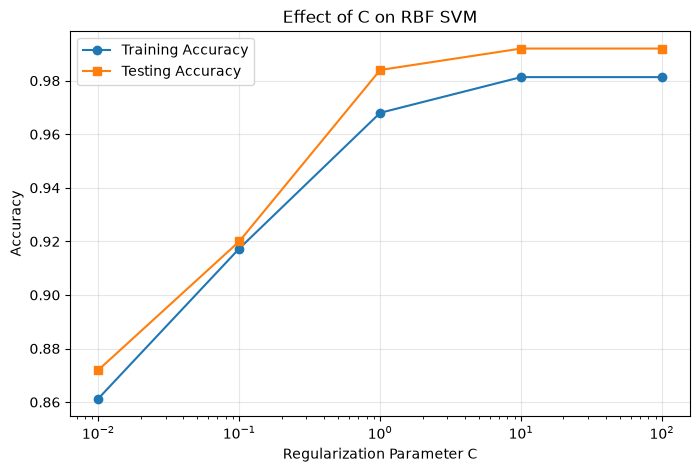

In [82]:
plt.figure(figsize=(8, 5))

plt.plot(
    C_df["C"],
    C_df["Train Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    C_df["C"],
    C_df["Test Accuracy"],
    marker="s",
    label="Testing Accuracy"
)

plt.xscale("log")
plt.xlabel("Regularization Parameter C")
plt.ylabel("Accuracy")
plt.title("Effect of C on RBF SVM")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

the Effect of RBF Gamma

In [83]:
gamma_values = [0.01, 0.1, 1, 10, 100]

gamma_results = []
gamma_models = {}

for gamma in gamma_values:

    model = SVC(
        kernel="rbf",
        C=1.0,
        gamma=gamma
    )

    model.fit(X_train_scaled, y_train)

    train_predictions = model.predict(X_train_scaled)
    test_predictions = model.predict(X_test_scaled)

    gamma_results.append({
        "Gamma": gamma,
        "Train Accuracy": accuracy_score(
            y_train, train_predictions
        ),
        "Test Accuracy": accuracy_score(
            y_test, test_predictions
        ),
        "Test F1": f1_score(
            y_test, test_predictions
        )
    })

    gamma_models[gamma] = model

gamma_df = pd.DataFrame(gamma_results)

print(gamma_df.round(4).to_string(index=False))

 Gamma  Train Accuracy  Test Accuracy  Test F1
  0.01          0.8587          0.864   0.8618
  0.10          0.8773          0.848   0.8430
  1.00          0.9760          0.984   0.9836
 10.00          0.9867          0.984   0.9836
100.00          0.9947          0.944   0.9412


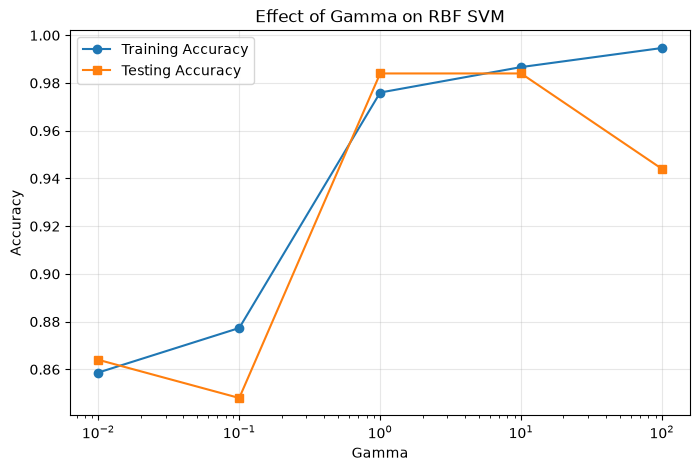

In [84]:
plt.figure(figsize=(8, 5))

plt.plot(
    gamma_df["Gamma"],
    gamma_df["Train Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    gamma_df["Gamma"],
    gamma_df["Test Accuracy"],
    marker="s",
    label="Testing Accuracy"
)

plt.xscale("log")
plt.xlabel("Gamma")
plt.ylabel("Accuracy")
plt.title("Effect of Gamma on RBF SVM")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

Gamma Changes the Decision Boundary

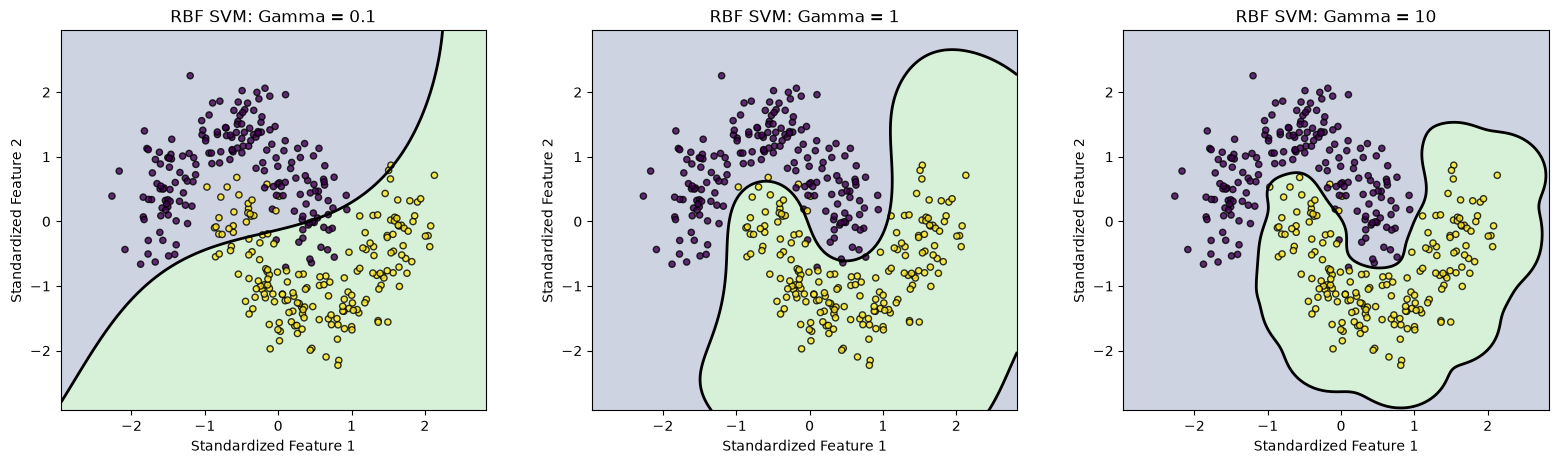

In [85]:
import numpy as np
import matplotlib.pyplot as plt

gamma_values_to_plot = [0.1, 1, 10]

x_min = X_train_scaled[:, 0].min() - 0.7
x_max = X_train_scaled[:, 0].max() + 0.7

y_min = X_train_scaled[:, 1].min() - 0.7
y_max = X_train_scaled[:, 1].max() + 0.7

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.column_stack([
    xx.ravel(),
    yy.ravel()
])

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, gamma in zip(axes, gamma_values_to_plot):

    model = gamma_models[gamma]

    predictions = model.predict(grid).reshape(xx.shape)

    scores = model.decision_function(grid).reshape(xx.shape)

    ax.contourf(
        xx,
        yy,
        predictions,
        alpha=0.25,
        levels=[-0.5, 0.5, 1.5]
    )

    ax.contour(
        xx,
        yy,
        scores,
        levels=[0],
        colors="black",
        linewidths=2
    )

    ax.scatter(
        X_train_scaled[:, 0],
        X_train_scaled[:, 1],
        c=y_train,
        edgecolors="black",
        s=20,
        alpha=0.8
    )

    ax.set_title(f"RBF SVM: Gamma = {gamma}")
    ax.set_xlabel("Standardized Feature 1")
    ax.set_ylabel("Standardized Feature 2")

fig.subplots_adjust(
    left=0.05,
    right=0.98,
    bottom=0.12,
    top=0.88,
    wspace=0.25
)

plt.show()

In [86]:
summary = pd.DataFrame([
    {
        "Experiment": "Polynomial Degree",
        "Best Setting": degree_df.loc[
            degree_df["Test F1"].idxmax(), "Degree"
        ],
        "Best Test Accuracy": degree_df["Test Accuracy"].max(),
        "Best Test F1": degree_df["Test F1"].max()
    },
    {
        "Experiment": "RBF Regularization",
        "Best Setting": C_df.loc[
            C_df["Test F1"].idxmax(), "C"
        ],
        "Best Test Accuracy": C_df.loc[
            C_df["Test F1"].idxmax(), "Test Accuracy"
        ],
        "Best Test F1": C_df["Test F1"].max()
    },
    {
        "Experiment": "RBF Gamma",
        "Best Setting": gamma_df.loc[
            gamma_df["Test F1"].idxmax(), "Gamma"
        ],
        "Best Test Accuracy": gamma_df.loc[
            gamma_df["Test F1"].idxmax(), "Test Accuracy"
        ],
        "Best Test F1": gamma_df["Test F1"].max()
    }
])

print(summary.round(4).to_string(index=False))

        Experiment  Best Setting  Best Test Accuracy  Best Test F1
 Polynomial Degree           5.0               0.992        0.9919
RBF Regularization         100.0               0.992        0.9920
         RBF Gamma           1.0               0.984        0.9836


 ### Part D - Final Comparison

In [87]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

# Load the original Banknote dataset.

df = pd.read_csv("BankNoteAuthentication.csv")

feature_names = [
    "variance",
    "skewness",
    "curtosis",
    "entropy"
]

X = df[feature_names].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

# Stratified split preserves the class proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training classes:", np.unique(y_train))
print("Testing classes:", np.unique(y_test))

Training shape: (1029, 4)
Testing shape: (343, 4)
Training classes: [0 1]
Testing classes: [0 1]


Train the two Decision Trees

In [88]:
from sklearn.tree import DecisionTreeClassifier

# Manual Decision Tree
manual_tree_final = DecisionTreeScratch(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1
)

manual_tree_final.fit(X_train.tolist(), y_train.tolist())

# Scikit-learn Decision Tree
sklearn_tree_final = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

sklearn_tree_final.fit(X_train, y_train)

print("Both Decision Trees trained successfully.")

Both Decision Trees trained successfully.


Scale the data for SVM


In [89]:
from sklearn.preprocessing import StandardScaler

svm_scaler_final = StandardScaler()

X_train_scaled_final = svm_scaler_final.fit_transform(X_train)
X_test_scaled_final = svm_scaler_final.transform(X_test)

# Convert labels: 0 -> -1 and 1 -> +1
y_train_svm_final = np.where(y_train == 0, -1, 1)
y_test_svm_final = np.where(y_test == 0, -1, 1)

print("SVM training shape:", X_train_scaled_final.shape)
print("SVM testing shape:", X_test_scaled_final.shape)

SVM training shape: (1029, 4)
SVM testing shape: (343, 4)


Train the manual Linear SVM

In [90]:
manual_svm_final = LinearSVMScratch(
    C=1.0,
    learning_rate=0.01,
    epochs=2000
)

manual_svm_final.fit(
    X_train_scaled_final,
    y_train_svm_final
)

print("Manual Linear SVM trained successfully.")
print("Final objective:", manual_svm_final.loss_history[-1])

Manual Linear SVM trained successfully.
Final objective: 0.6881344584437055


Train Scikit-learn Linear SVM and RBF SVM

In [91]:
from sklearn.svm import SVC

# Scikit-learn Linear SVM
sklearn_linear_svm_final = SVC(
    kernel="linear",
    C=1.0
)

sklearn_linear_svm_final.fit(
    X_train_scaled_final,
    y_train_svm_final
)

# Scikit-learn RBF SVM
rbf_svm_final = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

rbf_svm_final.fit(
    X_train_scaled_final,
    y_train_svm_final
)

print("Scikit-learn Linear SVM trained successfully.")
print("Scikit-learn RBF SVM trained successfully.")

Scikit-learn Linear SVM trained successfully.
Scikit-learn RBF SVM trained successfully.


Evaluate all five models

In [92]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


def calculate_metrics(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred,
            pos_label=1,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred,
            pos_label=1,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred,
            pos_label=1,
            zero_division=0
        )
    }


# Generate predictions.
# Manual SVM returns -1/+1, so convert to 0/1.
manual_tree_train_pred = manual_tree_final.predict(
    X_train.tolist()
)

manual_tree_test_pred = manual_tree_final.predict(
    X_test.tolist()
)

sklearn_tree_train_pred = sklearn_tree_final.predict(X_train)
sklearn_tree_test_pred = sklearn_tree_final.predict(X_test)

manual_svm_train_pred = np.where(
    manual_svm_final.predict(X_train_scaled_final) == -1,
    0, 1
)

manual_svm_test_pred = np.where(
    manual_svm_final.predict(X_test_scaled_final) == -1,
    0, 1
)

linear_svm_train_pred = np.where(
    sklearn_linear_svm_final.predict(X_train_scaled_final) == -1,
    0, 1
)

linear_svm_test_pred = np.where(
    sklearn_linear_svm_final.predict(X_test_scaled_final) == -1,
    0, 1
)

rbf_svm_train_pred = np.where(
    rbf_svm_final.predict(X_train_scaled_final) == -1,
    0, 1
)

rbf_svm_test_pred = np.where(
    rbf_svm_final.predict(X_test_scaled_final) == -1,
    0, 1
)


models_predictions = {
    "Manual Decision Tree": (
        manual_tree_train_pred,
        manual_tree_test_pred
    ),
    "Scikit-learn Decision Tree": (
        sklearn_tree_train_pred,
        sklearn_tree_test_pred
    ),
    "Manual Linear SVM": (
        manual_svm_train_pred,
        manual_svm_test_pred
    ),
    "Scikit-learn Linear SVM": (
        linear_svm_train_pred,
        linear_svm_test_pred
    ),
    "Scikit-learn RBF SVM": (
        rbf_svm_train_pred,
        rbf_svm_test_pred
    )
}

comparison_results = []

for model_name, (train_pred, test_pred) in models_predictions.items():

    train_metrics = calculate_metrics(y_train, train_pred)
    test_metrics = calculate_metrics(y_test, test_pred)

    comparison_results.append({
        "Model": model_name,
        "Train Accuracy": train_metrics["Accuracy"],
        "Test Accuracy": test_metrics["Accuracy"],
        "Test Precision": test_metrics["Precision"],
        "Test Recall": test_metrics["Recall"],
        "Test F1-score": test_metrics["F1-score"]
    })

final_comparison = pd.DataFrame(comparison_results)

print(
    final_comparison
    .round(4)
    .to_string(index=False)
)

                     Model  Train Accuracy  Test Accuracy  Test Precision  Test Recall  Test F1-score
      Manual Decision Tree          0.9971         0.9854          0.9742       0.9934         0.9837
Scikit-learn Decision Tree          0.9971         0.9854          0.9742       0.9934         0.9837
         Manual Linear SVM          0.8533         0.8921          0.9528       0.7961         0.8674
   Scikit-learn Linear SVM          0.9874         0.9767          0.9500       1.0000         0.9744
      Scikit-learn RBF SVM          1.0000         1.0000          1.0000       1.0000         1.0000


Compare the confusion matrices

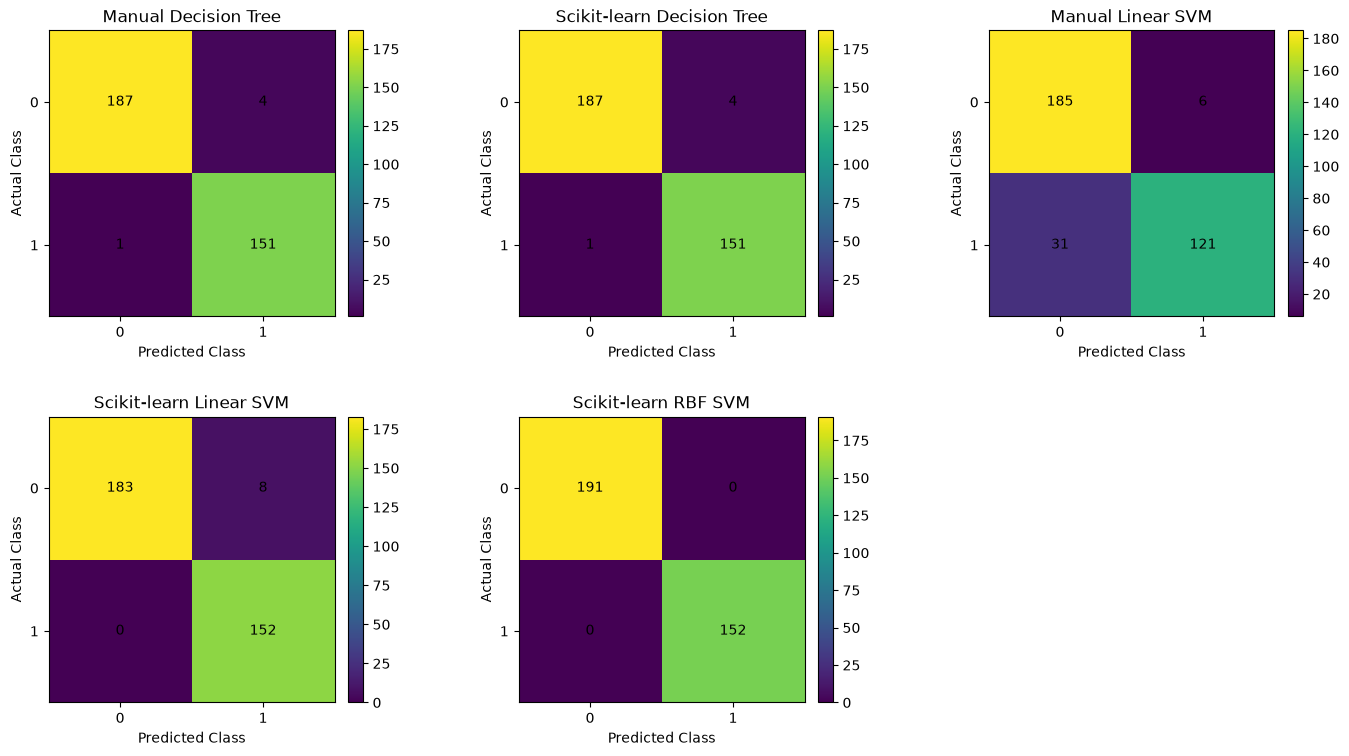

In [93]:
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8)
)

axes = axes.ravel()

for ax, (model_name, (_, test_pred)) in zip(
    axes, models_predictions.items()
):

    cm = confusion_matrix(
        y_test,
        test_pred,
        labels=[0, 1]
    )

    image = ax.imshow(cm, interpolation="nearest")

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center"
            )

    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

# Hide the unused sixth subplot.
axes[5].axis("off")

fig.subplots_adjust(
    left=0.06,
    right=0.98,
    bottom=0.08,
    top=0.92,
    wspace=0.35,
    hspace=0.35
)

plt.show()

| Model                      | Interpretability                                                             |
| -------------------------- | ---------------------------------------------------------------------------- |
| Manual Decision Tree       | High; splitting rules can be inspected directly                              |
| Scikit-learn Decision Tree | High; the learned tree can be visualized                                     |
| Manual Linear SVM          | Moderate; predictions depend on a weighted linear combination of features    |
| Scikit-learn Linear SVM    | Moderate; feature weights help explain the decision function                 |
| Scikit-learn RBF SVM       | Lower; the nonlinear decision function is more difficult to explain directly |


#### Feature scaling

Decision Trees: Usually do not require feature scaling. Their numerical split ordering is preserved by standardization.

Linear SVMs: Generally benefit from scaling because feature magnitudes affect the optimization and regularization.

RBF SVM: Scaling is particularly important because its kernel depends on squared distances:

$$ K(x,z)=e^{-\gamma\|x-z\|^2} $$

Without appropriate scaling, features with larger numerical ranges can dominate the distance calculation.

For your final comparison, both SVM implementations use the same training-fitted scaler.

#### Overfitting

| Pattern                              | Interpretation                                |
| ------------------------------------ | --------------------------------------------- |
| Both accuracies are high and similar | Good evidence of generalization on this split |
| Training accuracy is much higher     | Possible overfitting                          |
| Both accuracies are low              | Possible underfitting                         |
| Test accuracy is unexpectedly higher | Can occur because of sampling variation       |


Your Decision Trees have a maximum depth of five, which limits their complexity.

The RBF SVM can represent nonlinear boundaries. Its complexity depends on parameters such as \(C\) and \(\gamma\).

The manual SVM's performance also depends on whether the optimization process has converged sufficiently.

A single train-test split cannot establish that a model will generalize reliably across all possible datasets. Cross-validation would provide a more robust assessment.

#### Model complexity

| Model                      | Main complexity considerations                                              |
| -------------------------- | --------------------------------------------------------------------------- |
| Manual Decision Tree       | Repeated threshold evaluation; potentially expensive training               |
| Scikit-learn Decision Tree | Optimized tree construction; complexity depends on the number of nodes      |
| Manual Linear SVM          | Iterative optimization; depends on training size, feature count, and epochs |
| Scikit-learn Linear SVM    | Depends on the solver and optimization settings                             |
| Scikit-learn RBF SVM       | Kernel computations can become expensive as training size increases         |
